In [ ]:
!pip -q install datasets transformers accelerate scikit-learn pandas numpy matplotlib fairlearn

In [ ]:
import sys
import torch
import pandas as pd
import sklearn
import datasets
import transformers

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Datasets:", datasets.__version__)
print("Transformers:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())


Python: 3.13.16
PyTorch: 2.11.0+cu130
Pandas: 2.2.3
Scikit-learn: 1.6.1
Datasets: 4.8.5
Transformers: 5.22.0
GPU available: True


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

file_path = "/content/drive/MyDrive/AI Fairness Research/train.csv"

df = pd.read_csv(file_path, nrows=100)

print("Number of comments:", len(df))

print("\nAvailable columns:")
print(df.columns.tolist())

Number of comments: 100

Available columns:
['id', 'target', 'comment_text', 'severe_toxicity', 'obscene', 'identity_attack', 'insult', 'threat', 'asian', 'atheist', 'bisexual', 'black', 'buddhist', 'christian', 'female', 'heterosexual', 'hindu', 'homosexual_gay_or_lesbian', 'intellectual_or_learning_disability', 'jewish', 'latino', 'male', 'muslim', 'other_disability', 'other_gender', 'other_race_or_ethnicity', 'other_religion', 'other_sexual_orientation', 'physical_disability', 'psychiatric_or_mental_illness', 'transgender', 'white', 'created_date', 'publication_id', 'parent_id', 'article_id', 'rating', 'funny', 'wow', 'sad', 'likes', 'disagree', 'sexual_explicit', 'identity_annotator_count', 'toxicity_annotator_count']


In [ ]:
display(df[["comment_text", "target"]].head(10))

,comment_text,target
0,"This is so cool. It's like, 'would you want yo...",0.000000
1,Thank you!! This would make my life a lot less...,0.000000
2,This is such an urgent design problem; kudos t...,0.000000
3,Is this something I'll be able to install on m...,0.000000
4,haha you guys are a bunch of losers.,0.893617
5,ur a sh*tty comment.,0.666667
6,hahahahahahahahhha suck it.,0.457627
7,FFFFUUUUUUUUUUUUUUU,0.000000
8,The ranchers seem motivated by mostly by greed...,0.000000
9,It was a great show. Not a combo I'd of expect...,0.000000


In [ ]:
# Convert toxicity scores into binary labels

df["label"] = (df["target"] >= 0.5).astype(int)

# Display the results
display(df[["comment_text", "target", "label"]].head(10))

,comment_text,target,label
0,"This is so cool. It's like, 'would you want yo...",0.000000,0
1,Thank you!! This would make my life a lot less...,0.000000,0
2,This is such an urgent design problem; kudos t...,0.000000,0
3,Is this something I'll be able to install on m...,0.000000,0
4,haha you guys are a bunch of losers.,0.893617,1
5,ur a sh*tty comment.,0.666667,1
6,hahahahahahahahhha suck it.,0.457627,0
7,FFFFUUUUUUUUUUUUUUU,0.000000,0
8,The ranchers seem motivated by mostly by greed...,0.000000,0
9,It was a great show. Not a combo I'd of expect...,0.000000,0


In [ ]:
# Count the number of comments in each class

print(df["label"].value_counts())

label
0    92
1     8
Name: count, dtype: int64


In [ ]:
# Calculate the percentage of each class

print(df["label"].value_counts(normalize=True) * 100)

label
0    92.0
1     8.0
Name: proportion, dtype: float64


In [ ]:
# Identity columns used in our research

identity_columns = [
    "male",
    "female",
    "homosexual_gay_or_lesbian",
    "christian",
    "jewish",
    "muslim",
    "black",
    "white",
    "psychiatric_or_mental_illness"
]

# Display identity annotations
display(df[identity_columns].head(10))

,male,female,homosexual_gay_or_lesbian,christian,jewish,muslim,black,white,psychiatric_or_mental_illness
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


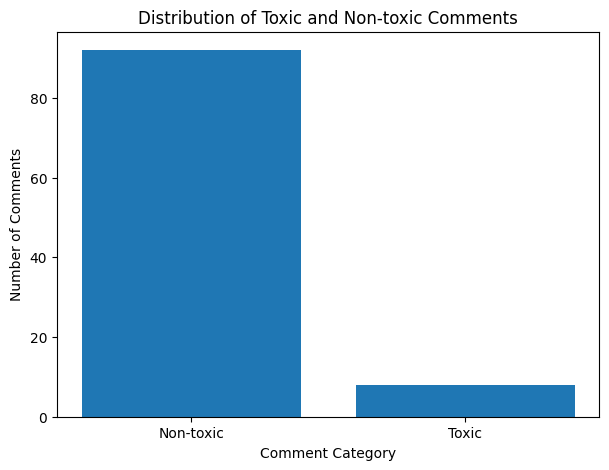

In [ ]:
import matplotlib.pyplot as plt

# Count comments in each class
counts = df["label"].value_counts().reindex([0, 1], fill_value=0)

# Create a bar chart
plt.figure(figsize=(7, 5))

plt.bar(
    ["Non-toxic", "Toxic"],
    counts.values
)

plt.title("Distribution of Toxic and Non-toxic Comments")
plt.xlabel("Comment Category")
plt.ylabel("Number of Comments")

plt.show()

In [ ]:
import pandas as pd

file_path = "/content/drive/MyDrive/AI Fairness Research/train.csv"

# Load the complete dataset
df_full = pd.read_csv(file_path)

print("Total comments:", len(df_full))
print("Total columns:", len(df_full.columns))

display(df_full.head(5))

Total comments: 1804874
Total columns: 45


,id,target,comment_text,severe_toxicity,obscene,identity_attack,insult,threat,asian,atheist,...,article_id,rating,funny,wow,sad,likes,disagree,sexual_explicit,identity_annotator_count,toxicity_annotator_count
0,59848,0.000000,"This is so cool. It's like, 'would you want yo...",0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,...,2006,rejected,0,0,0,0,0,0.0,0,4
1,59849,0.000000,Thank you!! This would make my life a lot less...,0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,...,2006,rejected,0,0,0,0,0,0.0,0,4
2,59852,0.000000,This is such an urgent design problem; kudos t...,0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,...,2006,rejected,0,0,0,0,0,0.0,0,4
3,59855,0.000000,Is this something I'll be able to install on m...,0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,...,2006,rejected,0,0,0,0,0,0.0,0,4
4,59856,0.893617,haha you guys are a bunch of losers.,0.021277,0.0,0.021277,0.87234,0.0,0.0,0.0,...,2006,rejected,0,0,0,1,0,0.0,4,47


In [ ]:
# Check missing values in important columns

print("Missing comment text:",
      df_full["comment_text"].isna().sum())

print("Missing toxicity labels:",
      df_full["target"].isna().sum())

print("Duplicate IDs:",
      df_full["id"].duplicated().sum())

Missing comment text: 3
Missing toxicity labels: 0
Duplicate IDs: 0


In [ ]:
df_full["label"] = (
    df_full["target"] >= 0.5
).astype(int)

print("Toxicity distribution:")

print(df_full["label"].value_counts())

print("\nPercentages:")

print(
    df_full["label"].value_counts(
        normalize=True
    ) * 100
)

Toxicity distribution:
label
0    1660540
1     144334
Name: count, dtype: int64

Percentages:
label
0    92.003098
1     7.996902
Name: proportion, dtype: float64


In [ ]:
identity_columns = [
    "male",
    "female",
    "christian",
    "muslim",
    "black",
    "white"
]

for group in identity_columns:

    # Only count comments with an available annotation
    valid = df_full[group].notna()

    # Count comments with a strong identity-mention annotation
    count = (
        valid & (df_full[group] >= 0.5)
    ).sum()

    print(f"{group}: {count} comments")

male: 44484 comments
female: 53429 comments
christian: 40423 comments
muslim: 21006 comments
black: 14901 comments
white: 25082 comments


In [ ]:
# Step 1: Remove comments with missing text

df_clean = df_full.dropna(
    subset=["comment_text", "target"]
).copy()

# Step 2: Remove comments containing only whitespace

df_clean = df_clean[
    df_clean["comment_text"].str.strip().ne("")
].copy()

# Step 3: Create binary toxicity labels

df_clean["label"] = (
    df_clean["target"] >= 0.5
).astype(int)

# Step 4: Check the cleaned dataset

print("Original dataset size:", len(df_full))
print("Cleaned dataset size:", len(df_clean))
print("Removed comments:", len(df_full) - len(df_clean))

print("\nToxicity distribution:")
print(df_clean["label"].value_counts())

print("\nToxicity percentages:")
print(
    df_clean["label"].value_counts(
        normalize=True
    ) * 100
)

Original dataset size: 1804874
Cleaned dataset size: 1804871
Removed comments: 3

Toxicity distribution:
label
0    1660537
1     144334
Name: count, dtype: int64

Toxicity percentages:
label
0    92.003085
1     7.996915
Name: proportion, dtype: float64


In [ ]:
# Count duplicate comment texts

duplicate_texts = df_clean["comment_text"].duplicated().sum()

print("Duplicate comment texts:", duplicate_texts)

Duplicate comment texts: 24049


In [ ]:
# Find all comments whose text appears more than once

duplicates = df_clean[
    df_clean.duplicated(
        subset=["comment_text"],
        keep=False
    )
].copy()

print("Total rows belonging to duplicate groups:", len(duplicates))

print("Number of unique duplicated texts:",
      duplicates["comment_text"].nunique())

# Display some duplicate examples
display(
    duplicates[
        ["comment_text", "target", "label"]
    ].sort_values("comment_text").head(20)
)

Total rows belonging to duplicate groups: 34228
Number of unique duplicated texts: 10179


,comment_text,target,label
35274,""" Just another reminder that people are genera...",0.862069,1
35275,""" Just another reminder that people are genera...",0.795918,1
35276,""" Just another reminder that people are genera...",0.800000,1
1801314,""" Mr. Drumpf's speech before the Asian Pacific...",0.166667,0
1800939,""" Mr. Drumpf's speech before the Asian Pacific...",0.400000,0
1800998,""" Mr. Drumpf's speech before the Asian Pacific...",0.400000,0
619967,""" Turner had a long list of past driving offen...",0.166667,0
620011,""" Turner had a long list of past driving offen...",0.400000,0
26819,""" everything that's old is aew again""\nThat's ...",0.000000,0
26817,""" everything that's old is aew again""\nThat's ...",0.000000,0


In [ ]:
# Count the number of distinct binary labels for each comment

label_variations = (
    df_clean.groupby("comment_text")["label"]
    .nunique()
)

# Count comments with conflicting labels
conflicting_comments = (label_variations > 1).sum()

print("Unique comment texts with conflicting labels:",
      conflicting_comments)

Unique comment texts with conflicting labels: 596


In [ ]:
# Number of times each comment appears

duplicate_frequency = (
    df_clean["comment_text"].value_counts()
)

print("Most frequently repeated comments:")

display(duplicate_frequency.head(10))

Most frequently repeated comments:


,count
comment_text,
Well said.,184
No.,160
Exactly.,132
Yes.,127
Thank you.,120
Why?,118
"Sᴛᴀʀᴛ ᴡᴏʀᴋɪɴɢ ғʀᴏᴍ ʜᴏᴍᴇ! Gʀᴇᴀᴛ ᴊᴏʙ ғᴏʀ sᴛᴜᴅᴇɴᴛs, sᴛᴀʏ-ᴀᴛ-ʜᴏᴍᴇ ᴍᴏᴍs ᴏʀ ᴀɴʏᴏɴᴇ ɴᴇᴇᴅɪɴɢ ᴀɴ ᴇxᴛʀᴀ ɪɴᴄᴏᴍᴇ... Yᴏᴜ ᴏɴʟʏ ɴᴇᴇᴅ ᴀ ᴄᴏᴍᴘᴜᴛᴇʀ ᴀɴᴅ ᴀ ʀᴇʟɪᴀʙʟᴇ ɪɴᴛᴇʀɴᴇᴛ ᴄᴏɴɴᴇᴄᴛɪᴏɴ... Mᴀᴋᴇ $90 ʜᴏᴜʀʟʏ ᴀɴᴅ ᴜᴘ ᴛᴏ $12000 ᴀ ᴍᴏɴᴛʜ ʙʏ ғᴏʟʟᴏᴡɪɴɢ ʟɪɴᴋ ᴀᴛ ᴛʜᴇ ʙᴏᴛᴛᴏᴍ ᴀɴᴅ sɪɢɴɪɴɢ ᴜᴘ... Yᴏᴜ ᴄᴀɴ ʜᴀᴠᴇ ʏᴏᴜʀ ғɪʀsᴛ ᴄʜᴇᴄᴋ ʙʏ ᴛʜᴇ ᴇɴᴅ ᴏғ ᴛʜɪs ᴡᴇᴇᴋ... \n\n+++++++++http://www.cashapp24.com/",117
Exactly!,103
Well said!,100


In [ ]:
# STEP 1: Identify comments with conflicting binary labels

label_counts = (
    df_clean.groupby("comment_text")["label"]
    .nunique()
)

conflicting_texts = label_counts[label_counts > 1].index

print("Conflicting unique comments:", len(conflicting_texts))


# STEP 2: Remove all rows containing conflicting comments

df_no_conflicts = df_clean[
    ~df_clean["comment_text"].isin(conflicting_texts)
].copy()

print("Rows remaining after conflict removal:",
      len(df_no_conflicts))


# STEP 3: Keep one copy of each remaining comment

df_unique = df_no_conflicts.drop_duplicates(
    subset=["comment_text"],
    keep="first"
).copy()

print("Final unique comments:", len(df_unique))


# STEP 4: Verify results

print("Remaining duplicate texts:",
      df_unique["comment_text"].duplicated().sum())

print("Remaining conflicting labels:",
      (
          df_unique.groupby("comment_text")["label"]
          .nunique() > 1
      ).sum())

Conflicting unique comments: 596
Rows remaining after conflict removal: 1802794
Final unique comments: 1780226
Remaining duplicate texts: 0
Remaining conflicting labels: 0


In [ ]:
print("Final dataset size:", len(df_unique))

print("\nToxicity distribution:")
print(df_unique["label"].value_counts())

print("\nToxicity percentages:")
print(
    df_unique["label"].value_counts(
        normalize=True
    ) * 100
)

Final dataset size: 1780226

Toxicity distribution:
label
0    1638063
1     142163
Name: count, dtype: int64

Toxicity percentages:
label
0    92.014329
1     7.985671
Name: proportion, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

# Set a fixed random seed for reproducibility
RANDOM_STATE = 42

# First, select 30,000 comments from our cleaned dataset
df_sample, _ = train_test_split(
    df_unique,
    train_size=30000,
    stratify=df_unique["label"],
    random_state=RANDOM_STATE
)

print("Total sampled comments:", len(df_sample))

# Separate the testing dataset first
train_val, test_df = train_test_split(
    df_sample,
    test_size=5000,
    stratify=df_sample["label"],
    random_state=RANDOM_STATE
)

# Separate training and validation datasets
train_df, val_df = train_test_split(
    train_val,
    test_size=5000,
    stratify=train_val["label"],
    random_state=RANDOM_STATE
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Total sampled comments: 30000
Training: 20000
Validation: 5000
Testing: 5000


In [ ]:
# Check for overlapping comment IDs

train_ids = set(train_df["id"])
val_ids = set(val_df["id"])
test_ids = set(test_df["id"])

print("Train-Val overlap:", len(train_ids & val_ids))

print("Train-Test overlap:", len(train_ids & test_ids))

print("Val-Test overlap:", len(val_ids & test_ids))

# Check that all 30,000 comments are accounted for
print(
    "Total comments:",
    len(train_df) + len(val_df) + len(test_df)
)

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0
Total comments: 30000


In [ ]:
for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:

    print(f"\n{name} Dataset")

    print("Total comments:", len(data))

    print("Class counts:")
    print(data["label"].value_counts())

    print("Class percentages:")
    print(
        (
            data["label"]
            .value_counts(normalize=True) * 100
        ).round(2)
    )


Training Dataset
Total comments: 20000
Class counts:
label
0    18402
1     1598
Name: count, dtype: int64
Class percentages:
label
0    92.01
1     7.99
Name: proportion, dtype: float64

Validation Dataset
Total comments: 5000
Class counts:
label
0    4601
1     399
Name: count, dtype: int64
Class percentages:
label
0    92.02
1     7.98
Name: proportion, dtype: float64

Testing Dataset
Total comments: 5000
Class counts:
label
0    4601
1     399
Name: count, dtype: int64
Class percentages:
label
0    92.02
1     7.98
Name: proportion, dtype: float64


In [ ]:
import pandas as pd

identity_columns = [
    "male",
    "female",
    "christian",
    "muslim",
    "black",
    "white"
]

def check_group_distribution(data):

    results = []

    for group in identity_columns:

        # An annotation >= 0.5 indicates an identity mention
        mentions = data[group] >= 0.5

        # Count subgroup examples
        total = mentions.sum()

        # Count non-toxic examples mentioning the identity
        non_toxic = (
            mentions & (data["label"] == 0)
        ).sum()

        # Count toxic examples mentioning the identity
        toxic = (
            mentions & (data["label"] == 1)
        ).sum()

        results.append({
            "Group": group,
            "Total": total,
            "Non-toxic": non_toxic,
            "Toxic": toxic
        })

    return pd.DataFrame(results)


print("TRAINING DATASET")
display(check_group_distribution(train_df))

print("VALIDATION DATASET")
display(check_group_distribution(val_df))

print("TESTING DATASET")
display(check_group_distribution(test_df))

TRAINING DATASET


,Group,Total,Non-toxic,Toxic
0,male,480,410,70
1,female,607,524,83
2,christian,450,405,45
3,muslim,224,178,46
4,black,186,137,49
5,white,304,233,71


VALIDATION DATASET


,Group,Total,Non-toxic,Toxic
0,male,135,115,20
1,female,153,133,20
2,christian,125,113,12
3,muslim,58,40,18
4,black,27,18,9
5,white,61,44,17


TESTING DATASET


,Group,Total,Non-toxic,Toxic
0,male,114,95,19
1,female,146,123,23
2,christian,101,87,14
3,muslim,67,51,16
4,black,39,26,13
5,white,67,49,18


In [ ]:
identity_columns = [
    "male",
    "female",
    "christian",
    "muslim",
    "black",
    "white"
]

# Exclude all examples already used in our splits
used_ids = set(
    pd.concat([
        train_df["id"],
        val_df["id"],
        test_df["id"]
    ])
)

available_df = df_unique[
    ~df_unique["id"].isin(used_ids)
].copy()

print("Unused comments available:", len(available_df))

Unused comments available: 1750226


In [ ]:
# Identify comments mentioning at least one selected identity

identity_mentions = (
    available_df[identity_columns] >= 0.5
).any(axis=1)

identity_pool = available_df[
    identity_mentions
].copy()

print(
    "Unused comments mentioning at least one identity:",
    len(identity_pool)
)

print("\nToxicity distribution:")

print(identity_pool["label"].value_counts())

Unused comments mentioning at least one identity: 147271

Toxicity distribution:
label
0    123469
1     23802
Name: count, dtype: int64


In [ ]:
def available_group_counts(data):

    results = []

    for group in identity_columns:

        mentions = data[group] >= 0.5

        non_toxic = (
            mentions & (data["label"] == 0)
        ).sum()

        toxic = (
            mentions & (data["label"] == 1)
        ).sum()

        results.append({
            "Group": group,
            "Available non-toxic": non_toxic,
            "Available toxic": toxic
        })

    return pd.DataFrame(results)


display(available_group_counts(identity_pool))

,Group,Available non-toxic,Available toxic
0,male,36996,6507
1,female,45088,7113
2,christian,36025,3573
3,muslim,15790,4640
4,black,9978,4540
5,white,17541,6824


In [ ]:
import pandas as pd

RANDOM_STATE = 42

identity_columns = [
    "male",
    "female",
    "christian",
    "muslim",
    "black",
    "white"
]

# Our target number of examples per group
N_NON_TOXIC = 300
N_TOXIC = 200

selected_ids = set()

for group in identity_columns:

    print(f"\nSampling group: {group}")

    for label, target_n in [
        (0, N_NON_TOXIC),
        (1, N_TOXIC)
    ]:

        # Find eligible comments for this group
        eligible = available_df[
            (available_df[group] >= 0.5) &
            (available_df["label"] == label) &
            (~available_df["id"].isin(selected_ids))
        ]

        # Select examples
        n = min(target_n, len(eligible))

        sampled = eligible.sample(
            n=n,
            random_state=RANDOM_STATE
        )

        # Store selected IDs
        selected_ids.update(sampled["id"])

        print(
            f"Label {label}: selected {len(sampled)} comments"
        )

# Create the final enriched evaluation dataset
enriched_test_df = available_df[
    available_df["id"].isin(selected_ids)
].copy()

print("\nFinal enriched test size:", len(enriched_test_df))


Sampling group: male
Label 0: selected 300 comments
Label 1: selected 200 comments

Sampling group: female
Label 0: selected 300 comments
Label 1: selected 200 comments

Sampling group: christian
Label 0: selected 300 comments
Label 1: selected 200 comments

Sampling group: muslim
Label 0: selected 300 comments
Label 1: selected 200 comments

Sampling group: black
Label 0: selected 300 comments
Label 1: selected 200 comments

Sampling group: white
Label 0: selected 300 comments
Label 1: selected 200 comments

Final enriched test size: 3000


In [ ]:
print("ENRICHED TEST DATASET")

display(
    check_group_distribution(enriched_test_df)
)

print("\nOverall class distribution:")

print(
    enriched_test_df["label"].value_counts()
)

ENRICHED TEST DATASET


,Group,Total,Non-toxic,Toxic
0,male,934,564,370
1,female,926,573,353
2,christian,700,433,267
3,muslim,656,363,293
4,black,727,420,307
5,white,887,502,385



Overall class distribution:
label
0    1800
1    1200
Name: count, dtype: int64


In [ ]:
# Check for overlapping IDs

enriched_ids = set(enriched_test_df["id"])

print(
    "Train-Enriched overlap:",
    len(train_ids & enriched_ids)
)

print(
    "Validation-Enriched overlap:",
    len(val_ids & enriched_ids)
)

print(
    "Test-Enriched overlap:",
    len(test_ids & enriched_ids)
)

# Check for duplicate texts

print(
    "Duplicate texts within enriched set:",
    enriched_test_df["comment_text"].duplicated().sum()
)

Train-Enriched overlap: 0
Validation-Enriched overlap: 0
Test-Enriched overlap: 0
Duplicate texts within enriched set: 0


In [ ]:
import os

output_dir = (
    "/content/drive/MyDrive/"
    "AI Fairness Research/processed"
)

os.makedirs(output_dir, exist_ok=True)

train_df.to_csv(
    f"{output_dir}/train_processed.csv",
    index=False
)

val_df.to_csv(
    f"{output_dir}/val_processed.csv",
    index=False
)

test_df.to_csv(
    f"{output_dir}/test_processed.csv",
    index=False
)

enriched_test_df.to_csv(
    f"{output_dir}/enriched_test_processed.csv",
    index=False
)

print("All four datasets saved successfully!")

All four datasets saved successfully!


Run from here

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import os

# Folder containing our processed datasets
data_dir = "/content/drive/MyDrive/AI Fairness Research/processed"

# Load previously saved datasets
train_df = pd.read_csv(
    f"{data_dir}/train_processed.csv"
)

val_df = pd.read_csv(
    f"{data_dir}/val_processed.csv"
)

test_df = pd.read_csv(
    f"{data_dir}/test_processed.csv"
)

enriched_test_df = pd.read_csv(
    f"{data_dir}/enriched_test_processed.csv"
)

print("All datasets loaded successfully!")

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Enriched testing:", len(enriched_test_df))

All datasets loaded successfully!
Training: 20000
Validation: 5000
Testing: 5000
Enriched testing: 3000


In [ ]:
print("Training dataset:")
display(train_df[["comment_text", "target", "label"]].head())

print("\nTraining labels:")
print(train_df["label"].value_counts())

print("\nMissing comment text:")
print(train_df["comment_text"].isna().sum())

Training dataset:


,comment_text,target,label
0,"Yes, it's relative. You don't find it offensiv...",0.0,0
1,"And yet 99Bandit, the apology and payment will...",0.0,0
2,"""Trump junkie"" doesn't mean pro-trump. It's l...",0.2,0
3,A very good question.\nAnd one Liberals will a...,0.2,0
4,"Millions of women didn't vote, now they are co...",0.4,0



Training labels:
label
0    18402
1     1598
Name: count, dtype: int64

Missing comment text:
0


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/AI Fairness Research"

MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
FIGURES_DIR = os.path.join(PROJECT_DIR, "figures")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

print("Research directories are ready.")

Research directories are ready.


In [ ]:
# STEP 2: Verify training and validation data

print("Training dataset shape:", train_df.shape)
print("Validation dataset shape:", val_df.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nTraining labels:")
print(train_df["label"].value_counts())

print("\nValidation labels:")
print(val_df["label"].value_counts())

Training dataset shape: (20000, 46)
Validation dataset shape: (5000, 46)

Training columns:
['id', 'target', 'comment_text', 'severe_toxicity', 'obscene', 'identity_attack', 'insult', 'threat', 'asian', 'atheist', 'bisexual', 'black', 'buddhist', 'christian', 'female', 'heterosexual', 'hindu', 'homosexual_gay_or_lesbian', 'intellectual_or_learning_disability', 'jewish', 'latino', 'male', 'muslim', 'other_disability', 'other_gender', 'other_race_or_ethnicity', 'other_religion', 'other_sexual_orientation', 'physical_disability', 'psychiatric_or_mental_illness', 'transgender', 'white', 'created_date', 'publication_id', 'parent_id', 'article_id', 'rating', 'funny', 'wow', 'sad', 'likes', 'disagree', 'sexual_explicit', 'identity_annotator_count', 'toxicity_annotator_count', 'label']

Training labels:
label
0    18402
1     1598
Name: count, dtype: int64

Validation labels:
label
0    4601
1     399
Name: count, dtype: int64


In [ ]:
# Confirm all required columns are present

required_columns = [
    "id",
    "comment_text",
    "target",
    "label"
]

for name, data in [
    ("Training", train_df),
    ("Validation", val_df)
]:
    missing_columns = [
        col for col in required_columns
        if col not in data.columns
    ]

    assert not missing_columns, (
        f"{name} dataset is missing: {missing_columns}"
    )

# Verify dataset sizes
assert len(train_df) == 20000
assert len(val_df) == 5000

# Verify toxicity labels
assert set(train_df["label"].unique()) == {0, 1}
assert set(val_df["label"].unique()) == {0, 1}

# Verify there are no missing texts
assert train_df["comment_text"].notna().all()
assert val_df["comment_text"].notna().all()

# Verify that the labels match the original annotations
assert (
    train_df["label"].to_numpy()
    == (train_df["target"].to_numpy() >= 0.5).astype(int)
).all()

assert (
    val_df["label"].to_numpy()
    == (val_df["target"].to_numpy() >= 0.5).astype(int)
).all()

# Verify there are no repeated texts across splits
train_texts = set(train_df["comment_text"])
val_texts = set(val_df["comment_text"])

assert train_texts.isdisjoint(val_texts)

# Verify there are no overlapping IDs
assert set(train_df["id"]).isdisjoint(set(val_df["id"]))

print("All dataset integrity checks passed!")

All dataset integrity checks passed!


In [ ]:
# Training inputs
X_train = train_df["comment_text"].astype(str)

# Training labels
y_train = train_df["label"].astype(int)

# Validation inputs
X_val = val_df["comment_text"].astype(str)

# Validation labels
y_val = val_df["label"].astype(int)

print("Training comments:", len(X_train))
print("Training labels:", len(y_train))

print("Validation comments:", len(X_val))
print("Validation labels:", len(y_val))

Training comments: 20000
Training labels: 20000
Validation comments: 5000
Validation labels: 5000


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Define the TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    lowercase=True,
    dtype="float64"
)

# Learn the vocabulary from the training comments
# and convert those comments into numerical features
X_train_tfidf = tfidf.fit_transform(X_train)

# Convert validation comments using the SAME vocabulary
X_val_tfidf = tfidf.transform(X_val)

print("TF-IDF transformation completed!")

print("Training matrix shape:", X_train_tfidf.shape)
print("Validation matrix shape:", X_val_tfidf.shape)

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:2043: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float64 'dtype' will be converted to np.float64.
  warnings.warn(


TF-IDF transformation completed!
Training matrix shape: (20000, 20000)
Validation matrix shape: (5000, 20000)


In [ ]:
feature_names = tfidf.get_feature_names_out()

print("Total vocabulary features:", len(feature_names))

print("\nFirst 30 features:")
print(feature_names[:30])

Total vocabulary features: 20000

First 30 features:
['00' '000' '000 00' '000 000' '000 in' '000 people' '000 per' '000 to'
 '000 year' '000 years' '01' '02' '03' '04' '05' '06' '07' '08' '09' '10'
 '10 000' '10 billion' '10 million' '10 of' '10 year' '10 years' '100'
 '100 000' '100 million' '100 of']


In [ ]:
from scipy.sparse import issparse

print("Training matrix is sparse:", issparse(X_train_tfidf))
print("Validation matrix is sparse:", issparse(X_val_tfidf))

Training matrix is sparse: True
Validation matrix is sparse: True


In [ ]:
from sklearn.linear_model import LogisticRegression

import time

# Create the Logistic Regression model
lr_model = LogisticRegression(
    C=1.0,
    solver="liblinear",
    max_iter=1000,
    class_weight=None,
    random_state=42
)

# Start timing
start_time = time.time()

# Train the model
lr_model.fit(X_train_tfidf, y_train)

# Calculate training time
training_time = time.time() - start_time

print("Logistic Regression training completed!")

print(f"Training time: {training_time:.2f} seconds")

print("Model classes:", lr_model.classes_)

print("Training iterations:", lr_model.n_iter_)

Logistic Regression training completed!
Training time: 0.21 seconds
Model classes: [0 1]
Training iterations: [9]


In [ ]:
# Predict toxicity labels for validation comments

val_predictions = lr_model.predict(X_val_tfidf)

print("First 20 predicted labels:")
print(val_predictions[:20])

print("\nFirst 20 actual labels:")
print(y_val.to_numpy()[:20])

First 20 predicted labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

First 20 actual labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [ ]:
# Predict scores for the toxic class (label 1)

val_probabilities = lr_model.predict_proba(
    X_val_tfidf
)[:, 1]

print("First 20 predicted toxicity scores:")

print(val_probabilities[:20])

First 20 predicted toxicity scores:
[0.09490964 0.11115005 0.07794163 0.04558906 0.05533321 0.03048986
 0.0411636  0.04921967 0.11608732 0.15489614 0.0283152  0.12021186
 0.02738515 0.07430336 0.14070642 0.05625619 0.09868826 0.02265558
 0.04615204 0.04740133]


In [ ]:
# Create a table containing actual labels and predictions

validation_results = val_df[
    ["id", "comment_text", "target", "label"]
].copy()

validation_results["predicted_label"] = val_predictions

validation_results["predicted_score"] = val_probabilities

# Identify correct and incorrect predictions
validation_results["correct"] = (
    validation_results["label"]
    == validation_results["predicted_label"]
)

display(
    validation_results[
        [
            "comment_text",
            "label",
            "predicted_label",
            "predicted_score",
            "correct"
        ]
    ].head(15)
)

,comment_text,label,predicted_label,predicted_score,correct
0,Yeah cause you've seen how easy it is to embar...,0,0,0.094910,True
1,Alt left marxist mother using her son as a pol...,0,0,0.111150,True
2,"""they're simply pointing out the selective out...",0,0,0.077942,True
3,Canada is thankful for that.,0,0,0.045589,True
4,"Tridentinus , it was mercy which was show by a...",0,0,0.055333,True
5,I learned to ski here in my first winter in Al...,0,0,0.030490,True
6,"I was. Yeah, that offense was very ineffectiv...",0,0,0.041164,True
7,'I wish there was reverse attraction\nthat wou...,0,0,0.049220,True
8,Why are tolls OK? To me this is at least one p...,0,0,0.116087,True
9,1) My shorts aren't anywhere other than on my ...,0,0,0.154896,True


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

import pandas as pd

# Calculate confusion matrix values
tn, fp, fn, tp = confusion_matrix(
    y_val,
    val_predictions,
    labels=[0, 1]
).ravel()

# Calculate performance metrics
metrics = {
    "Accuracy": accuracy_score(
        y_val, val_predictions
    ),

    "Precision (Toxic)": precision_score(
        y_val, val_predictions, zero_division=0
    ),

    "Recall (Toxic)": recall_score(
        y_val, val_predictions, zero_division=0
    ),

    "F1 (Toxic)": f1_score(
        y_val, val_predictions, zero_division=0
    ),

    "Macro F1": f1_score(
        y_val, val_predictions,
        average="macro",
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_val, val_probabilities
    ),

    "Average Precision": average_precision_score(
        y_val, val_probabilities
    ),

    "False Positive Rate": (
        fp / (fp + tn)
        if (fp + tn) > 0
        else float("nan")
    )
}

metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Metric", "Value"]
)

print("MODEL A — VALIDATION RESULTS")

display(metrics_df.round(4))

MODEL A — VALIDATION RESULTS


,Metric,Value
0,Accuracy,0.9236
1,Precision (Toxic),0.9474
2,Recall (Toxic),0.0451
3,F1 (Toxic),0.0861
4,Macro F1,0.5231
5,ROC-AUC,0.8612
6,Average Precision,0.5059
7,False Positive Rate,0.0002


In [ ]:
print("CLASSIFICATION REPORT")

print(
    classification_report(
        y_val,
        val_predictions,
        labels=[0, 1],
        target_names=["Non-toxic", "Toxic"],
        digits=4,
        zero_division=0
    )
)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Non-toxic     0.9235    0.9998    0.9601      4601
       Toxic     0.9474    0.0451    0.0861       399

    accuracy                         0.9236      5000
   macro avg     0.9354    0.5224    0.5231      5000
weighted avg     0.9254    0.9236    0.8904      5000



In [ ]:
cm = confusion_matrix(
    y_val,
    val_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nTotal predictions:", tn + fp + fn + tp)

True Negatives: 4600
False Positives: 1
False Negatives: 381
True Positives: 18

Total predictions: 5000


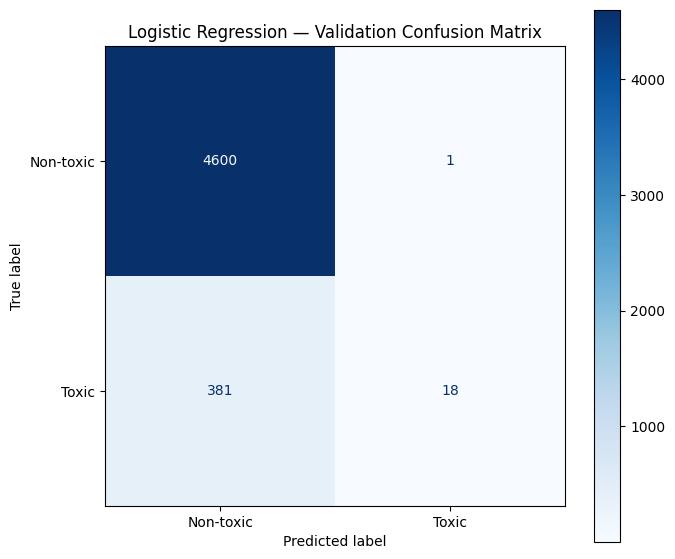

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-toxic", "Toxic"]
).plot(
    ax=ax,
    values_format="d",
    cmap="Blues"
)

plt.title(
    "Logistic Regression — Validation Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "logistic_regression_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Non-toxic comments incorrectly predicted as toxic

false_positives = validation_results[
    (validation_results["label"] == 0) &
    (validation_results["predicted_label"] == 1)
].copy()

print("Number of false positives:", len(false_positives))

display(
    false_positives[
        [
            "comment_text",
            "target",
            "predicted_score"
        ]
    ].head(10)
)

Number of false positives: 1


,comment_text,target,predicted_score
279,That makes one liar lying to another liar on a...,0.0,0.506078


In [ ]:
identity_columns = [
    "male",
    "female",
    "christian",
    "muslim",
    "black",
    "white"
]

In [ ]:
import numpy as np

fairness_results = []

for group in identity_columns:

    # Identify comments with a positive identity-mention annotation
    group_mask = val_df[group].ge(0.5).fillna(False)

    group_true = y_val[group_mask]
    group_pred = val_predictions[group_mask.to_numpy()]

    # Number of available subgroup examples
    total = len(group_true)

    # Actual non-toxic and toxic examples
    n_non_toxic = (group_true == 0).sum()
    n_toxic = (group_true == 1).sum()

    # Confusion matrix for this subgroup
    tn_g, fp_g, fn_g, tp_g = confusion_matrix(
        group_true,
        group_pred,
        labels=[0, 1]
    ).ravel()

    # False-positive rate
    fpr = (
        fp_g / (fp_g + tn_g)
        if (fp_g + tn_g) > 0
        else np.nan
    )

    # False-negative rate
    fnr = (
        fn_g / (fn_g + tp_g)
        if (fn_g + tp_g) > 0
        else np.nan
    )

    # Subgroup F1-score
    group_f1 = (
        f1_score(
            group_true,
            group_pred,
            zero_division=0
        )
        if total > 0
        else np.nan
    )

    fairness_results.append({
        "Group": group,
        "Total": total,
        "Non-toxic": n_non_toxic,
        "Toxic": n_toxic,
        "False Positives": fp_g,
        "False Negatives": fn_g,
        "FPR": fpr,
        "FNR": fnr,
        "Toxic F1": group_f1
    })

fairness_df = pd.DataFrame(fairness_results)

print("MODEL A — VALIDATION SUBGROUP FAIRNESS")

display(fairness_df.round(4))

MODEL A — VALIDATION SUBGROUP FAIRNESS


,Group,Total,Non-toxic,Toxic,False Positives,False Negatives,FPR,FNR,Toxic F1
0,male,135,115,20,0,20,0.0,1.0000,0.0000
1,female,153,133,20,0,20,0.0,1.0000,0.0000
2,christian,125,113,12,0,12,0.0,1.0000,0.0000
3,muslim,58,40,18,0,18,0.0,1.0000,0.0000
4,black,27,18,9,0,9,0.0,1.0000,0.0000
5,white,61,44,17,0,16,0.0,0.9412,0.1111


In [ ]:
valid_fpr = fairness_df["FPR"].dropna()

fpr_gap = (
    valid_fpr.max() - valid_fpr.min()
)

print("Highest subgroup FPR:", round(valid_fpr.max(), 4))
print("Lowest subgroup FPR:", round(valid_fpr.min(), 4))

print("FPR disparity gap:", round(fpr_gap, 4))

Highest subgroup FPR: 0.0
Lowest subgroup FPR: 0.0
FPR disparity gap: 0.0


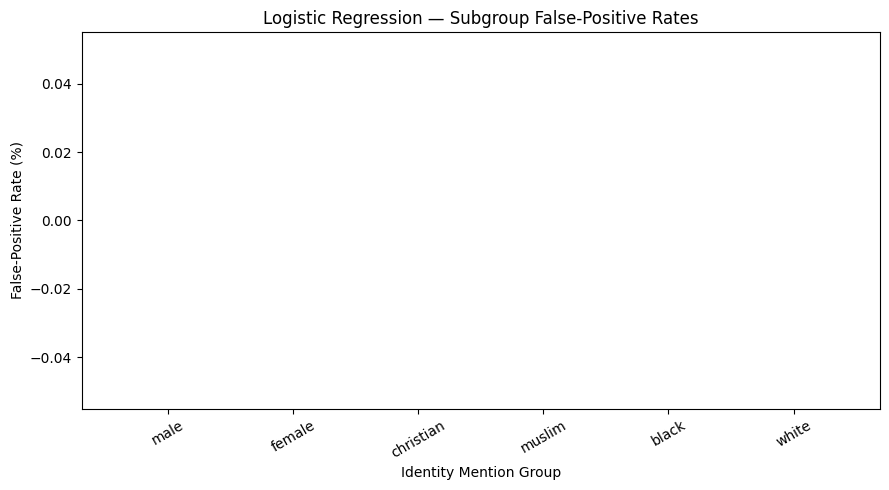

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    fairness_df["Group"],
    fairness_df["FPR"] * 100
)

plt.title(
    "Logistic Regression — Subgroup False-Positive Rates"
)

plt.xlabel("Identity Mention Group")
plt.ylabel("False-Positive Rate (%)")

plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "logistic_regression_subgroup_fpr_validation.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import joblib

tfidf_path = os.path.join(
    MODEL_DIR,
    "tfidf_vectorizer.joblib"
)

joblib.dump(tfidf, tfidf_path)

print("TF-IDF vectorizer saved successfully!")
print("Location:", tfidf_path)

TF-IDF vectorizer saved successfully!
Location: /content/drive/MyDrive/AI Fairness Research/models/tfidf_vectorizer.joblib


In [ ]:
model_path = os.path.join(
    MODEL_DIR,
    "logistic_regression_baseline.joblib"
)

joblib.dump(lr_model, model_path)

print("Logistic Regression model saved successfully!")
print("Location:", model_path)

Logistic Regression model saved successfully!
Location: /content/drive/MyDrive/AI Fairness Research/models/logistic_regression_baseline.joblib


In [ ]:
# Save overall performance metrics

metrics_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "logistic_regression_validation_metrics.csv"
    ),
    index=False
)

# Save subgroup fairness metrics

fairness_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "logistic_regression_validation_fairness.csv"
    ),
    index=False
)

# Save validation predictions

validation_results.to_csv(
    os.path.join(
        RESULTS_DIR,
        "logistic_regression_validation_predictions.csv"
    ),
    index=False
)

print("All validation results saved successfully!")

All validation results saved successfully!


In [ ]:
import json
import sklearn
import sys

experiment_config = {
    "experiment_name": "Model A - Classical ML Baseline",
    "model": "Logistic Regression",
    "vectorizer": "TF-IDF",
    "training_samples": len(train_df),
    "validation_samples": len(val_df),
    "random_seed": 42,
    "label_threshold": 0.5,
    "prediction_threshold": 0.5,
    "tfidf_settings": {
        "max_features": 20000,
        "ngram_range": [1, 2],
        "min_df": 2,
        "max_df": 0.95,
        "sublinear_tf": True,
        "lowercase": True
    },
    "logistic_regression_settings": {
        "C": 1.0,
        "solver": "liblinear",
        "max_iter": 1000,
        "class_weight": None
    },
    "software_versions": {
        "python": sys.version.split()[0],
        "scikit_learn": sklearn.__version__
    },
    "training_time_seconds": training_time,
    "evaluation_split": "validation",
    "test_data_used": False
}

config_path = os.path.join(
    RESULTS_DIR,
    "logistic_regression_config.json"
)

with open(config_path, "w") as f:
    json.dump(
        experiment_config,
        f,
        indent=4
    )

print("Experiment configuration saved!")

Experiment configuration saved!


In [ ]:
# Reload the saved vectorizer
loaded_tfidf = joblib.load(tfidf_path)

# Reload the saved classifier
loaded_model = joblib.load(model_path)

# Transform validation comments
X_val_loaded = loaded_tfidf.transform(X_val)

# Generate predictions again
loaded_predictions = loaded_model.predict(X_val_loaded)

# Compare with our original predictions
import numpy as np

predictions_match = np.array_equal(
    val_predictions,
    loaded_predictions
)

print("Reloaded predictions match:", predictions_match)

assert predictions_match, "Saved model verification failed!"

print("Saved model verification successful!")

Reloaded predictions match: True
Saved model verification successful!


## Model A: TF-IDF + Logistic Regression

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

PROJECT_DIR = "/content/drive/MyDrive/AI Fairness Research"

DATA_DIR = os.path.join(PROJECT_DIR, "processed")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
FIGURES_DIR = os.path.join(PROJECT_DIR, "figures")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

print("All libraries imported successfully!")
print("Project directory:", PROJECT_DIR)

All libraries imported successfully!
Project directory: /content/drive/MyDrive/AI Fairness Research


In [ ]:
train_df = pd.read_csv(
    os.path.join(DATA_DIR, "train_processed.csv")
)

val_df = pd.read_csv(
    os.path.join(DATA_DIR, "val_processed.csv")
)

print("Training dataset:", len(train_df))
print("Validation dataset:", len(val_df))

print("\nValidation label distribution:")
print(val_df["label"].value_counts())

Training dataset: 20000
Validation dataset: 5000

Validation label distribution:
label
0    4601
1     399
Name: count, dtype: int64


In [ ]:
tfidf_path = os.path.join(
    MODEL_DIR,
    "tfidf_vectorizer.joblib"
)

model_path = os.path.join(
    MODEL_DIR,
    "logistic_regression_baseline.joblib"
)

# Verify saved files exist
assert os.path.exists(tfidf_path), "TF-IDF file not found!"
assert os.path.exists(model_path), "Model file not found!"

# Reload the files you saved on Day 4
tfidf = joblib.load(tfidf_path)
lr_model = joblib.load(model_path)

print("TF-IDF vectorizer loaded successfully!")
print("Logistic Regression model loaded successfully!")

TF-IDF vectorizer loaded successfully!
Logistic Regression model loaded successfully!


In [ ]:
# Extract validation texts and correct labels
X_val = val_df["comment_text"].astype(str)
y_val = val_df["label"].astype(int)

# Convert comments into TF-IDF features
X_val_tfidf = tfidf.transform(X_val)

# Generate toxicity scores
val_probabilities = lr_model.predict_proba(
    X_val_tfidf
)[:, 1]

# Generate baseline predictions at threshold 0.50
val_predictions = (
    val_probabilities >= 0.5
).astype(int)

print("Validation examples:", len(y_val))
print("Predicted scores:", len(val_probabilities))

print("\nBaseline confusion matrix:")
print(confusion_matrix(y_val, val_predictions, labels=[0, 1]))

print("\nToxic F1 at threshold 0.50:")
print(round(f1_score(y_val, val_predictions), 4))

Validation examples: 5000
Predicted scores: 5000

Baseline confusion matrix:
[[4600    1]
 [ 381   18]]

Toxic F1 at threshold 0.50:
0.0861


In [ ]:
# STEP 7: Threshold comparison experiment

thresholds = np.arange(0.05, 0.96, 0.05)

threshold_results = []

for threshold in thresholds:

    # Convert predicted probabilities to binary labels
    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    # Calculate evaluation metrics
    precision = precision_score(
        y_val, predictions, zero_division=0
    )

    recall = recall_score(
        y_val, predictions, zero_division=0
    )

    f1 = f1_score(
        y_val, predictions, zero_division=0
    )

    accuracy = accuracy_score(
        y_val, predictions
    )

    fpr = fp / (fp + tn)

    # Store the results
    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Toxic F1": f1,
        "FPR": fpr,
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn
    })

threshold_df = pd.DataFrame(threshold_results)

print("THRESHOLD COMPARISON RESULTS")

display(threshold_df.round(4))

THRESHOLD COMPARISON RESULTS


,Threshold,Accuracy,Precision,Recall,Toxic F1,FPR,TP,FP,TN,FN
0,0.05,0.4118,0.1151,0.9524,0.2053,0.6351,380,2922,1679,19
1,0.10,0.8360,0.2859,0.7043,0.4067,0.1526,281,702,3899,118
2,0.15,0.9224,0.5144,0.4912,0.5026,0.0402,196,185,4416,203
3,0.20,0.9332,0.6738,0.3158,0.4300,0.0133,126,61,4540,273
4,0.25,0.9320,0.7658,0.2130,0.3333,0.0057,85,26,4575,314
5,0.30,0.9304,0.8400,0.1579,0.2658,0.0026,63,12,4589,336
6,0.35,0.9284,0.9020,0.1153,0.2044,0.0011,46,5,4596,353
7,0.40,0.9260,0.8919,0.0827,0.1514,0.0009,33,4,4597,366
8,0.45,0.9248,0.8966,0.0652,0.1215,0.0007,26,3,4598,373
9,0.50,0.9236,0.9474,0.0451,0.0861,0.0002,18,1,4600,381


In [ ]:
baseline_row = threshold_df[
    np.isclose(threshold_df["Threshold"], 0.50)
]

display(baseline_row.round(4))

assert len(baseline_row) == 1

assert int(baseline_row.iloc[0]["TP"]) == 18
assert int(baseline_row.iloc[0]["FP"]) == 1
assert int(baseline_row.iloc[0]["TN"]) == 4600
assert int(baseline_row.iloc[0]["FN"]) == 381

print("Original baseline verified successfully!")

,Threshold,Accuracy,Precision,Recall,Toxic F1,FPR,TP,FP,TN,FN
9,0.5,0.9236,0.9474,0.0451,0.0861,0.0002,18,1,4600,381


Original baseline verified successfully!


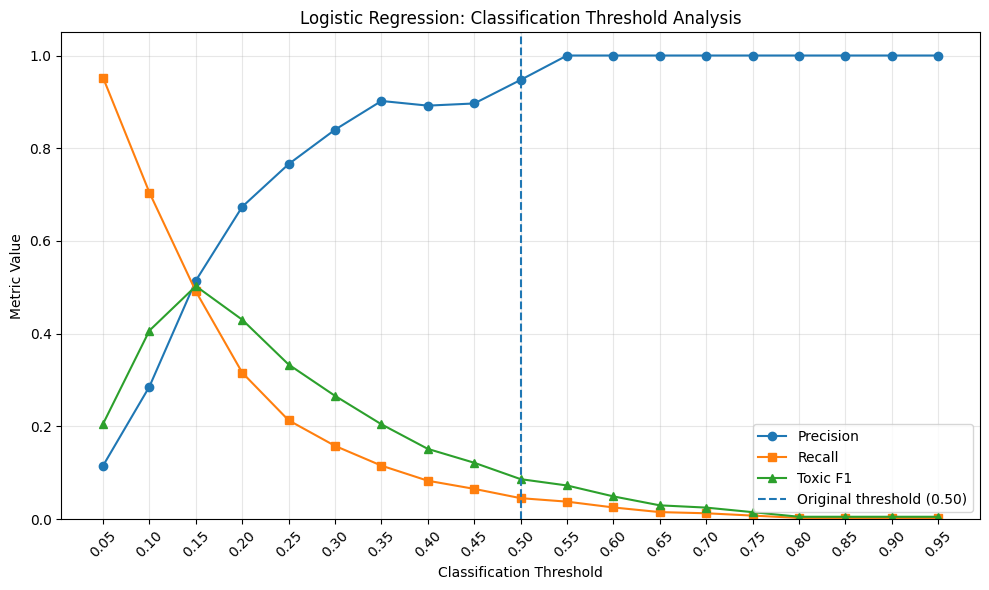

Figure saved to: /content/drive/MyDrive/AI Fairness Research/figures/logistic_regression_threshold_analysis.png


In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="s",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Toxic F1"],
    marker="^",
    label="Toxic F1"
)

plt.axvline(
    x=0.50,
    linestyle="--",
    label="Original threshold (0.50)"
)

plt.title(
    "Logistic Regression: Classification Threshold Analysis"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Metric Value")

plt.ylim(0, 1.05)
plt.xticks(thresholds, rotation=45)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save to Google Drive
figure_path = os.path.join(
    FIGURES_DIR,
    "logistic_regression_threshold_analysis.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", figure_path)

In [ ]:
# Find the row with the highest Toxic F1

best_index = threshold_df["Toxic F1"].idxmax()

best_result = threshold_df.loc[best_index]

best_threshold = float(best_result["Threshold"])

print("BEST VALIDATION THRESHOLD RESULTS")
print("--------------------------------")

print("Best threshold:", best_threshold)

print(
    "Precision:",
    round(best_result["Precision"], 4)
)

print(
    "Recall:",
    round(best_result["Recall"], 4)
)

print(
    "Toxic F1:",
    round(best_result["Toxic F1"], 4)
)

print(
    "False Positive Rate:",
    round(best_result["FPR"], 4)
)

print(
    "True Positives:",
    int(best_result["TP"])
)

print(
    "False Positives:",
    int(best_result["FP"])
)

print(
    "False Negatives:",
    int(best_result["FN"])
)

BEST VALIDATION THRESHOLD RESULTS
--------------------------------
Best threshold: 0.15
Precision: 0.5144
Recall: 0.4912
Toxic F1: 0.5026
False Positive Rate: 0.0402
True Positives: 196
False Positives: 185
False Negatives: 203


In [ ]:
baseline_result = threshold_df[
    np.isclose(threshold_df["Threshold"], 0.50)
].iloc[0]

comparison_df = pd.DataFrame({
    "Metric": [
        "Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "Toxic F1",
        "FPR",
        "True Positives",
        "False Positives",
        "False Negatives"
    ],

    "Original Model": [
        0.50,
        baseline_result["Accuracy"],
        baseline_result["Precision"],
        baseline_result["Recall"],
        baseline_result["Toxic F1"],
        baseline_result["FPR"],
        baseline_result["TP"],
        baseline_result["FP"],
        baseline_result["FN"]
    ],

    "Threshold-Adjusted Model": [
        best_threshold,
        best_result["Accuracy"],
        best_result["Precision"],
        best_result["Recall"],
        best_result["Toxic F1"],
        best_result["FPR"],
        best_result["TP"],
        best_result["FP"],
        best_result["FN"]
    ]
})

print("ORIGINAL VS THRESHOLD-ADJUSTED MODEL")

display(comparison_df.round(4))

ORIGINAL VS THRESHOLD-ADJUSTED MODEL


,Metric,Original Model,Threshold-Adjusted Model
0,Threshold,0.5000,0.1500
1,Accuracy,0.9236,0.9224
2,Precision,0.9474,0.5144
3,Recall,0.0451,0.4912
4,Toxic F1,0.0861,0.5026
5,FPR,0.0002,0.0402
6,True Positives,18.0000,196.0000
7,False Positives,1.0000,185.0000
8,False Negatives,381.0000,203.0000


In [ ]:
# Save all threshold results
threshold_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "logistic_regression_threshold_experiment.csv"
    ),
    index=False
)

# Save original-vs-adjusted comparison
comparison_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "logistic_regression_threshold_comparison.csv"
    ),
    index=False
)

# Save selected threshold
threshold_config = {
    "experiment": "Logistic Regression Threshold Optimization",
    "selection_dataset": "validation",
    "selection_metric": "toxic_class_f1",
    "candidate_thresholds": threshold_df[
        "Threshold"
    ].tolist(),
    "original_threshold": 0.50,
    "selected_threshold": best_threshold,
    "selected_validation_f1": float(
        best_result["Toxic F1"]
    ),
    "test_data_used": False
}

with open(
    os.path.join(
        RESULTS_DIR,
        "logistic_regression_threshold_config.json"
    ),
    "w"
) as f:
    json.dump(threshold_config, f, indent=4)

print("All threshold experiment results saved successfully!")

All threshold experiment results saved successfully!


In [ ]:
required_files = [
    "logistic_regression_threshold_experiment.csv",
    "logistic_regression_threshold_comparison.csv",
    "logistic_regression_threshold_config.json"
]

print("SAVED EXPERIMENT FILES")
print("----------------------")

for filename in required_files:
    file_path = os.path.join(RESULTS_DIR, filename)

    if os.path.exists(file_path):
        print("SAVED:", filename)
    else:
        print("MISSING:", filename)

figure_file = os.path.join(
    FIGURES_DIR,
    "logistic_regression_threshold_analysis.png"
)

print(
    "\nThreshold figure saved:",
    os.path.exists(figure_file)
)

SAVED EXPERIMENT FILES
----------------------
SAVED: logistic_regression_threshold_experiment.csv
SAVED: logistic_regression_threshold_comparison.csv
SAVED: logistic_regression_threshold_config.json

Threshold figure saved: True


In [ ]:

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

PROJECT_DIR = "/content/drive/MyDrive/AI Fairness Research"
DATA_DIR = os.path.join(PROJECT_DIR, "processed")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
FIGURES_DIR = os.path.join(PROJECT_DIR, "figures")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

train_df = pd.read_csv(
    os.path.join(DATA_DIR, "train_processed.csv")
)

val_df = pd.read_csv(
    os.path.join(DATA_DIR, "val_processed.csv")
)

tfidf = joblib.load(
    os.path.join(MODEL_DIR, "tfidf_vectorizer.joblib")
)

lr_model = joblib.load(
    os.path.join(MODEL_DIR, "logistic_regression_baseline.joblib")
)

X_train = train_df["comment_text"].astype(str)
y_train = train_df["label"].astype(int)

X_val = val_df["comment_text"].astype(str)
y_val = val_df["label"].astype(int)

X_train_tfidf = tfidf.transform(X_train)
X_val_tfidf = tfidf.transform(X_val)

val_probabilities = lr_model.predict_proba(
    X_val_tfidf
)[:, 1]

print("Training size:", len(train_df))
print("Validation size:", len(val_df))
print("Ready for balanced model training!")

Training size: 20000
Validation size: 5000
Ready for balanced model training!


In [ ]:
import time

balanced_lr = LogisticRegression(
    C=1.0,
    solver="liblinear",
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

start_time = time.time()

balanced_lr.fit(X_train_tfidf, y_train)

balanced_training_time = time.time() - start_time

print("Balanced model trained successfully!")
print("Training time:", round(balanced_training_time, 2))
print("Classes:", balanced_lr.classes_)
print("Iterations:", balanced_lr.n_iter_)

Balanced model trained successfully!
Training time: 0.58
Classes: [0 1]
Iterations: [6]


In [ ]:
balanced_probabilities = balanced_lr.predict_proba(
    X_val_tfidf
)[:, 1]

balanced_predictions_05 = (
    balanced_probabilities >= 0.50
).astype(int)

print("BALANCED MODEL AT THRESHOLD 0.50")

print(
    confusion_matrix(
        y_val,
        balanced_predictions_05,
        labels=[0, 1]
    )
)

print(
    "Toxic F1:",
    round(
        f1_score(y_val, balanced_predictions_05),
        4
    )
)

BALANCED MODEL AT THRESHOLD 0.50
[[4285  316]
 [ 163  236]]
Toxic F1: 0.4963


In [ ]:
thresholds = np.round(
    np.arange(0.05, 0.96, 0.05), 2
)

balanced_threshold_results = []

for threshold in thresholds:

    predictions = (
        balanced_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    balanced_threshold_results.append({
        "Threshold": float(threshold),
        "Accuracy": accuracy_score(
            y_val, predictions
        ),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "Toxic F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "FPR": fp / (fp + tn),
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn
    })

balanced_threshold_df = pd.DataFrame(
    balanced_threshold_results
)

display(balanced_threshold_df.round(4))

,Threshold,Accuracy,Precision,Recall,Toxic F1,FPR,TP,FP,TN,FN
0,0.05,0.0886,0.0805,1.0000,0.1490,0.9904,399,4557,44,0
1,0.10,0.1684,0.0872,0.9950,0.1603,0.9033,397,4156,445,2
2,0.15,0.3144,0.1024,0.9774,0.1854,0.7431,390,3419,1182,9
3,0.20,0.4690,0.1252,0.9449,0.2212,0.5723,377,2633,1968,22
4,0.25,0.6048,0.1561,0.8972,0.2660,0.4206,358,1935,2666,41
5,0.30,0.7054,0.1924,0.8421,0.3133,0.3065,336,1410,3191,63
6,0.35,0.7838,0.2369,0.7694,0.3622,0.2150,307,989,3612,92
7,0.40,0.8410,0.2920,0.6967,0.4115,0.1465,278,674,3927,121
8,0.45,0.8790,0.3581,0.6516,0.4622,0.1013,260,466,4135,139
9,0.50,0.9042,0.4275,0.5915,0.4963,0.0687,236,316,4285,163


In [ ]:
best_balanced_index = (
    balanced_threshold_df["Toxic F1"].idxmax()
)

best_balanced = balanced_threshold_df.loc[
    best_balanced_index
]

best_balanced_threshold = float(
    best_balanced["Threshold"]
)

print("BEST BALANCED MODEL RESULTS")
print("---------------------------")

print("Threshold:", best_balanced_threshold)
print("Accuracy:", round(best_balanced["Accuracy"], 4))
print("Precision:", round(best_balanced["Precision"], 4))
print("Recall:", round(best_balanced["Recall"], 4))
print("Toxic F1:", round(best_balanced["Toxic F1"], 4))
print("FPR:", round(best_balanced["FPR"], 4))
print("True Positives:", int(best_balanced["TP"]))
print("False Positives:", int(best_balanced["FP"]))
print("False Negatives:", int(best_balanced["FN"]))

BEST BALANCED MODEL RESULTS
---------------------------
Threshold: 0.6
Accuracy: 0.9294
Precision: 0.5747
Recall: 0.4436
Toxic F1: 0.5007
FPR: 0.0285
True Positives: 177
False Positives: 131
False Negatives: 222


In [ ]:
# Reload original threshold results from Day 5
unweighted_df = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "logistic_regression_threshold_experiment.csv"
    )
)

def get_result(df, threshold):
    return df.loc[
        np.isclose(df["Threshold"], threshold)
    ].iloc[0]

unweighted_original = get_result(unweighted_df, 0.50)
unweighted_optimized = unweighted_df.loc[
    unweighted_df["Toxic F1"].idxmax()
]

balanced_original = get_result(
    balanced_threshold_df, 0.50
)

balanced_optimized = balanced_threshold_df.loc[
    balanced_threshold_df["Toxic F1"].idxmax()
]

comparison_rows = []

for name, result in [
    ("A1: Unweighted 0.50", unweighted_original),
    ("A2: Unweighted optimized", unweighted_optimized),
    ("A3: Balanced 0.50", balanced_original),
    ("A4: Balanced optimized", balanced_optimized)
]:
    comparison_rows.append({
        "Experiment": name,
        "Threshold": result["Threshold"],
        "Accuracy": result["Accuracy"],
        "Precision": result["Precision"],
        "Recall": result["Recall"],
        "Toxic F1": result["Toxic F1"],
        "FPR": result["FPR"],
        "TP": int(result["TP"]),
        "FP": int(result["FP"]),
        "FN": int(result["FN"])
    })

comparison_4_df = pd.DataFrame(comparison_rows)

display(comparison_4_df.round(4))

,Experiment,Threshold,Accuracy,Precision,Recall,Toxic F1,FPR,TP,FP,FN
0,A1: Unweighted 0.50,0.50,0.9236,0.9474,0.0451,0.0861,0.0002,18,1,381
1,A2: Unweighted optimized,0.15,0.9224,0.5144,0.4912,0.5026,0.0402,196,185,203
2,A3: Balanced 0.50,0.50,0.9042,0.4275,0.5915,0.4963,0.0687,236,316,163
3,A4: Balanced optimized,0.60,0.9294,0.5747,0.4436,0.5007,0.0285,177,131,222


In [ ]:
print("Unweighted ROC-AUC:",
      round(roc_auc_score(y_val, val_probabilities), 4))

print("Balanced ROC-AUC:",
      round(roc_auc_score(y_val, balanced_probabilities), 4))

print("Unweighted Average Precision:",
      round(average_precision_score(y_val, val_probabilities), 4))

print("Balanced Average Precision:",
      round(average_precision_score(y_val, balanced_probabilities), 4))

Unweighted ROC-AUC: 0.8612
Balanced ROC-AUC: 0.8612
Unweighted Average Precision: 0.5059
Balanced Average Precision: 0.5113


In [ ]:
# Save as a separate model
joblib.dump(
    balanced_lr,
    os.path.join(
        MODEL_DIR,
        "logistic_regression_balanced.joblib"
    )
)

# Save threshold analysis
balanced_threshold_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "logistic_regression_balanced_thresholds.csv"
    ),
    index=False
)

# Save four-way comparison
comparison_4_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "logistic_regression_four_model_comparison.csv"
    ),
    index=False
)

# Save selected threshold
import json

with open(
    os.path.join(
        RESULTS_DIR,
        "logistic_regression_balanced_config.json"
    ),
    "w"
) as f:
    json.dump({
        "model": "LogisticRegression",
        "class_weight": "balanced",
        "C": 1.0,
        "solver": "liblinear",
        "max_iter": 1000,
        "random_state": 42,
        "selection_metric": "validation_toxic_f1",
        "selected_threshold": best_balanced_threshold,
        "candidate_thresholds": thresholds.tolist(),
        "training_time_seconds": balanced_training_time,
        "test_data_used": False
    }, f, indent=4)

print("Balanced model and results saved successfully!")

Balanced model and results saved successfully!


#Analyze Fairness Before Moving to DistilBERT

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score
)

PROJECT_DIR = "/content/drive/MyDrive/AI Fairness Research"
DATA_DIR = os.path.join(PROJECT_DIR, "processed")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
FIGURES_DIR = os.path.join(PROJECT_DIR, "figures")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

# Load training and validation data
train_df = pd.read_csv(
    os.path.join(DATA_DIR, "train_processed.csv")
)

val_df = pd.read_csv(
    os.path.join(DATA_DIR, "val_processed.csv")
)

# Load both saved models
tfidf = joblib.load(
    os.path.join(MODEL_DIR, "tfidf_vectorizer.joblib")
)

lr_model = joblib.load(
    os.path.join(MODEL_DIR, "logistic_regression_baseline.joblib")
)

balanced_lr = joblib.load(
    os.path.join(MODEL_DIR, "logistic_regression_balanced.joblib")
)

X_val = val_df["comment_text"].astype(str)
y_val = val_df["label"].astype(int)

X_val_tfidf = tfidf.transform(X_val)

# Generate scores
val_probabilities = lr_model.predict_proba(
    X_val_tfidf
)[:, 1]

balanced_probabilities = balanced_lr.predict_proba(
    X_val_tfidf
)[:, 1]

assert len(val_probabilities) == 5000
assert len(balanced_probabilities) == 5000

print("Models and validation data restored successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models and validation data restored successfully!


In [ ]:
model_predictions = {
    "A1_Unweighted_050": (
        val_probabilities >= 0.50
    ).astype(int),

    "A2_Unweighted_015": (
        val_probabilities >= 0.15
    ).astype(int),

    "A3_Balanced_050": (
        balanced_probabilities >= 0.50
    ).astype(int),

    "A4_Balanced_060": (
        balanced_probabilities >= 0.60
    ).astype(int)
}

print("Predictions generated for all four experiments.")

for model_name, predictions in model_predictions.items():
    print(
        model_name,
        "- Toxic predictions:",
        predictions.sum()
    )

Predictions generated for all four experiments.
A1_Unweighted_050 - Toxic predictions: 19
A2_Unweighted_015 - Toxic predictions: 381
A3_Balanced_050 - Toxic predictions: 552
A4_Balanced_060 - Toxic predictions: 308


In [ ]:
identity_columns = [
    "male",
    "female",
    "christian",
    "muslim",
    "black",
    "white"
]

fairness_results = []

for model_name, predictions in model_predictions.items():

    for group in identity_columns:

        # Select comments mentioning this identity
        group_mask = (
            val_df[group].notna()
            & (val_df[group] >= 0.5)
        ).to_numpy()

        # Extract correct labels and predictions
        group_true = y_val.to_numpy()[group_mask]
        group_pred = predictions[group_mask]

        # Calculate confusion matrix
        tn, fp, fn, tp = confusion_matrix(
            group_true,
            group_pred,
            labels=[0, 1]
        ).ravel()

        n_non_toxic = tn + fp
        n_toxic = tp + fn

        fpr = (
            fp / n_non_toxic
            if n_non_toxic > 0
            else np.nan
        )

        fnr = (
            fn / n_toxic
            if n_toxic > 0
            else np.nan
        )

        toxic_f1 = f1_score(
            group_true,
            group_pred,
            zero_division=0
        )

        fairness_results.append({
            "Model": model_name,
            "Group": group,
            "Total": len(group_true),
            "Non-toxic": n_non_toxic,
            "Toxic": n_toxic,
            "TP": tp,
            "FP": fp,
            "TN": tn,
            "FN": fn,
            "FPR": fpr,
            "FNR": fnr,
            "Toxic F1": toxic_f1
        })

fairness_comparison_df = pd.DataFrame(fairness_results)

display(fairness_comparison_df.round(4))

,Model,Group,Total,Non-toxic,Toxic,TP,FP,TN,FN,FPR,FNR,Toxic F1
0,A1_Unweighted_050,male,135,115,20,0,0,115,20,0.0000,1.0000,0.0000
1,A1_Unweighted_050,female,153,133,20,0,0,133,20,0.0000,1.0000,0.0000
2,A1_Unweighted_050,christian,125,113,12,0,0,113,12,0.0000,1.0000,0.0000
3,A1_Unweighted_050,muslim,58,40,18,0,0,40,18,0.0000,1.0000,0.0000
4,A1_Unweighted_050,black,27,18,9,0,0,18,9,0.0000,1.0000,0.0000
5,A1_Unweighted_050,white,61,44,17,1,0,44,16,0.0000,0.9412,0.1111
6,A2_Unweighted_015,male,135,115,20,10,11,104,10,0.0957,0.5000,0.4878
7,A2_Unweighted_015,female,153,133,20,12,11,122,8,0.0827,0.4000,0.5581
8,A2_Unweighted_015,christian,125,113,12,4,0,113,8,0.0000,0.6667,0.5000
9,A2_Unweighted_015,muslim,58,40,18,10,5,35,8,0.1250,0.4444,0.6061


In [ ]:
fpr_table = fairness_comparison_df.pivot(
    index="Group",
    columns="Model",
    values="FPR"
)

print("SUBGROUP FALSE-POSITIVE RATES (%)")

display((fpr_table * 100).round(2))

SUBGROUP FALSE-POSITIVE RATES (%)


Model,A1_Unweighted_050,A2_Unweighted_015,A3_Balanced_050,A4_Balanced_060
Group,,,,
black,0.0,33.33,55.56,27.78
christian,0.0,0.00,5.31,0.00
female,0.0,8.27,15.04,6.77
male,0.0,9.57,19.13,7.83
muslim,0.0,12.50,15.00,10.00
white,0.0,18.18,22.73,11.36


In [ ]:
gap_results = []

for model_name in model_predictions.keys():

    group_data = fairness_comparison_df[
        fairness_comparison_df["Model"] == model_name
    ]

    valid_fpr = group_data["FPR"].dropna()

    gap = valid_fpr.max() - valid_fpr.min()

    gap_results.append({
        "Model": model_name,
        "Highest FPR": valid_fpr.max(),
        "Lowest FPR": valid_fpr.min(),
        "FPR Gap": gap
    })

gap_df = pd.DataFrame(gap_results)

display(gap_df.round(4))

,Model,Highest FPR,Lowest FPR,FPR Gap
0,A1_Unweighted_050,0.0000,0.0000,0.0000
1,A2_Unweighted_015,0.3333,0.0000,0.3333
2,A3_Balanced_050,0.5556,0.0531,0.5025
3,A4_Balanced_060,0.2778,0.0000,0.2778


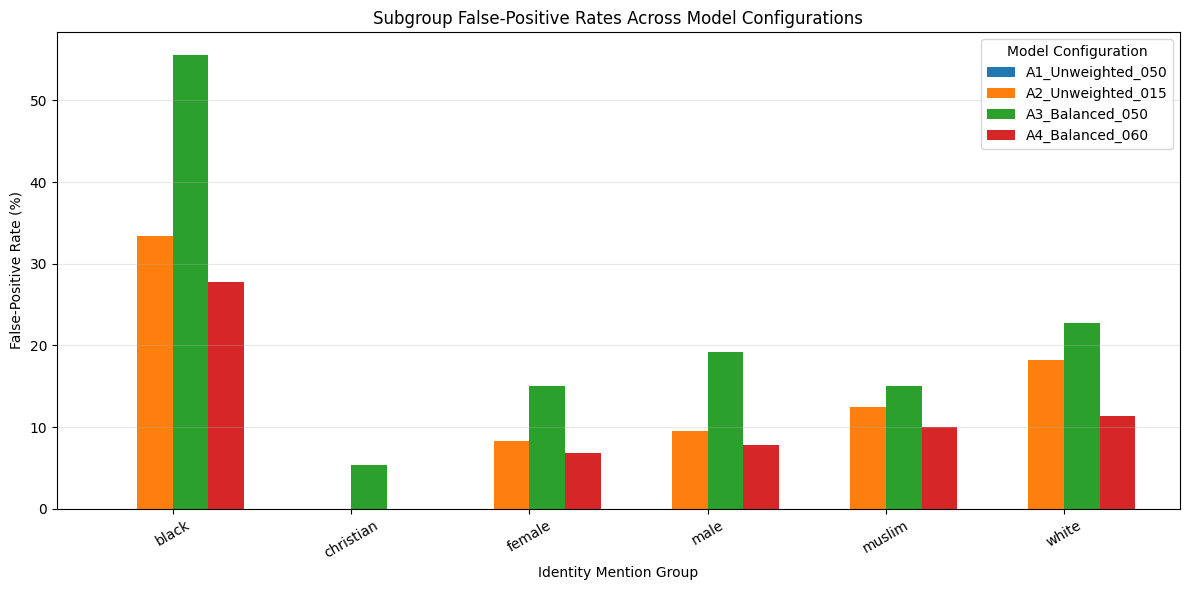

In [ ]:
ax = (fpr_table * 100).plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title(
    "Subgroup False-Positive Rates Across Model Configurations"
)

plt.xlabel("Identity Mention Group")
plt.ylabel("False-Positive Rate (%)")

plt.xticks(rotation=30)
plt.legend(title="Model Configuration")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "logistic_regression_four_model_fairness.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
fairness_comparison_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "logistic_regression_four_model_fairness.csv"
    ),
    index=False
)

gap_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "logistic_regression_four_model_fpr_gaps.csv"
    ),
    index=False
)

print("Fairness comparison results saved successfully!")

Fairness comparison results saved successfully!


# DistilBERT Transformer Baseline
## Experiment B1: Standard Fine-Tuning

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable — check Colab runtime settings")

assert torch.cuda.is_available(), "Please enable a GPU runtime."

PyTorch version: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4


In [ ]:
import torch
import pyarrow
import datasets
import transformers
import accelerate

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed
)

print("PyTorch:", torch.__version__)
print("PyArrow:", pyarrow.__version__)
print("Datasets:", datasets.__version__)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)

print("GPU available:", torch.cuda.is_available())

# Check Hugging Face dataset functionality
test_dataset = Dataset.from_dict({
    "text": ["Hello world", "This is a test"],
    "label": [0, 1]
})

print("Test dataset created:", len(test_dataset))
print("All required libraries are working!")

PyTorch: 2.14.1+cu130
PyArrow: 26.0.1
Datasets: 5.2.0
Transformers: 5.22.2
Accelerate: 1.15.0
GPU available: True
Test dataset created: 2
All required libraries are working!


In [ ]:
import os
import pandas as pd

from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/AI Fairness Research"
DATA_DIR = os.path.join(PROJECT_DIR, "processed")

BERT_MODEL_DIR = os.path.join(
    PROJECT_DIR, "models", "distilbert_standard"
)

BERT_RESULTS_DIR = os.path.join(
    PROJECT_DIR, "results", "distilbert_standard"
)

os.makedirs(BERT_MODEL_DIR, exist_ok=True)
os.makedirs(BERT_RESULTS_DIR, exist_ok=True)

# Load the training dataset
train_df = pd.read_csv(
    os.path.join(DATA_DIR, "train_processed.csv")
)

# Load the validation dataset
val_df = pd.read_csv(
    os.path.join(DATA_DIR, "val_processed.csv")
)

print("Training comments:", len(train_df))
print("Validation comments:", len(val_df))

print("\nTraining label distribution:")
print(train_df["label"].value_counts())

print("\nValidation label distribution:")
print(val_df["label"].value_counts())

# Verify dataset sizes
assert len(train_df) == 20000
assert len(val_df) == 5000

print("\nDataset verification successful!")

Mounted at /content/drive
Training comments: 20000
Validation comments: 5000

Training label distribution:
label
0    18402
1     1598
Name: count, dtype: int64

Validation label distribution:
label
0    4601
1     399
Name: count, dtype: int64

Dataset verification successful!


In [ ]:
from datasets import Dataset

train_hf = Dataset.from_pandas(
    train_df[
        ["comment_text", "label"]
    ].reset_index(drop=True)
)

val_hf = Dataset.from_pandas(
    val_df[
        ["comment_text", "label"]
    ].reset_index(drop=True)
)

print("Hugging Face datasets created!")

print("Training examples:", len(train_hf))
print("Validation examples:", len(val_hf))

print("Available features:", train_hf.column_names)

Hugging Face datasets created!
Training examples: 20000
Validation examples: 5000
Available features: ['comment_text', 'label']


In [ ]:
from transformers import AutoTokenizer

MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

sample_text = "This is a wonderful comment."

tokens = tokenizer(
    sample_text,
    truncation=True,
    max_length=256
)

print("Original text:", sample_text)

print(
    "Tokens:",
    tokenizer.convert_ids_to_tokens(
        tokens["input_ids"]
    )
)

print("Token IDs:", tokens["input_ids"])

print("\nTokenizer loaded successfully!")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Original text: This is a wonderful comment.
Tokens: ['[CLS]', 'this', 'is', 'a', 'wonderful', 'comment', '.', '[SEP]']
Token IDs: [101, 2023, 2003, 1037, 6919, 7615, 1012, 102]

Tokenizer loaded successfully!


In [ ]:
MAX_LENGTH = 256

def tokenize_comments(batch):
    return tokenizer(
        batch["comment_text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

tokenized_train = train_hf.map(
    tokenize_comments,
    batched=True,
    remove_columns=["comment_text"]
)

tokenized_val = val_hf.map(
    tokenize_comments,
    batched=True,
    remove_columns=["comment_text"]
)

print("Tokenization completed successfully!")

print("Training examples:", len(tokenized_train))
print("Validation examples:", len(tokenized_val))

print("Columns:", tokenized_train.column_names)

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Tokenization completed successfully!
Training examples: 20000
Validation examples: 5000
Columns: ['label', 'input_ids', 'token_type_ids', 'attention_mask']


In [ ]:
from transformers import (
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    set_seed
)

set_seed(42)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={
        0: "NON_TOXIC",
        1: "TOXIC"
    },
    label2id={
        "NON_TOXIC": 0,
        "TOXIC": 1
    }
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("DistilBERT loaded successfully!")
print("Number of classes:", model.config.num_labels)

print(
    "Model parameters:",
    sum(p.numel() for p in model.parameters())
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT loaded successfully!
Number of classes: 2
Model parameters: 66955010


In [ ]:
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(
            labels, predictions
        ),
        "precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "recall": recall_score(
            labels, predictions, zero_division=0
        ),
        "toxic_f1": f1_score(
            labels, predictions, zero_division=0
        ),
        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    }

print("Evaluation function ready!")

Evaluation function ready!


In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir=BERT_MODEL_DIR,

    num_train_epochs=2,
    learning_rate=2e-5,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,

    weight_decay=0.01,
    warmup_steps=0.1,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="toxic_f1",
    greater_is_better=True,

    save_total_limit=2,

    logging_strategy="steps",
    logging_steps=100,

    fp16=False,
    report_to="none",

    seed=42,
    data_seed=42
)

print("Training configuration created successfully!")
print("GPU device:", training_args.device)
print("Warmup fraction:", training_args.warmup_steps)

Training configuration created successfully!
GPU device: cuda:0
Warmup fraction: 0.1


In [ ]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("DistilBERT Trainer initialized successfully!")

DistilBERT Trainer initialized successfully!


In [ ]:
train_output = trainer.train()

print("DistilBERT training completed!")

print("\nTraining metrics:")
print(train_output.metrics)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,Toxic F1,Macro F1
1,0.342118,0.142081,0.946600,0.697605,0.583960,0.635744,0.803466
2,0.254674,0.193788,0.946000,0.685879,0.596491,0.638070,0.804447


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT training completed!

Training metrics:
{'train_runtime': 765.7079, 'train_samples_per_second': 52.239, 'train_steps_per_second': 3.265, 'total_flos': 1766827395439584.0, 'train_loss': 0.3404791229248047, 'epoch': 2.0}


In [ ]:
FINAL_BERT_DIR = os.path.join(
    BERT_MODEL_DIR,
    "best_model"
)

trainer.save_model(FINAL_BERT_DIR)
tokenizer.save_pretrained(FINAL_BERT_DIR)

print("Best DistilBERT model saved!")
print("Location:", FINAL_BERT_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best DistilBERT model saved!
Location: /content/drive/MyDrive/AI Fairness Research/models/distilbert_standard/best_model


In [ ]:
import numpy as np

from scipy.special import softmax

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

prediction_output = trainer.predict(tokenized_val)

logits = prediction_output.predictions

probabilities = softmax(logits, axis=1)

bert_val_probabilities = probabilities[:, 1]

bert_val_predictions = (
    bert_val_probabilities >= 0.5
).astype(int)

y_val = val_df["label"].to_numpy()

print("DISTILBERT VALIDATION RESULTS")
print("----------------------------")

print("\nConfusion matrix:")
print(
    confusion_matrix(
        y_val,
        bert_val_predictions,
        labels=[0, 1]
    )
)

print(
    "\nAccuracy:",
    round(accuracy_score(y_val, bert_val_predictions), 4)
)

print(
    "Precision:",
    round(
        precision_score(
            y_val, bert_val_predictions, zero_division=0
        ), 4
    )
)

print(
    "Recall:",
    round(
        recall_score(
            y_val, bert_val_predictions, zero_division=0
        ), 4
    )
)

print(
    "Toxic F1:",
    round(f1_score(y_val, bert_val_predictions), 4)
)

print(
    "Macro F1:",
    round(
        f1_score(
            y_val,
            bert_val_predictions,
            average="macro"
        ), 4
    )
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_val, bert_val_probabilities), 4)
)

print(
    "Average Precision:",
    round(
        average_precision_score(
            y_val, bert_val_probabilities
        ), 4
    )
)

DISTILBERT VALIDATION RESULTS
----------------------------

Confusion matrix:
[[4492  109]
 [ 161  238]]

Accuracy: 0.946
Precision: 0.6859
Recall: 0.5965
Toxic F1: 0.6381
Macro F1: 0.8044
ROC-AUC: 0.9463
Average Precision: 0.7147


In [ ]:
bert_validation_results = val_df[
    ["id", "label"]
].copy()

bert_validation_results["predicted_label"] = (
    bert_val_predictions
)

bert_validation_results["predicted_score"] = (
    bert_val_probabilities
)

bert_validation_results.to_csv(
    os.path.join(
        BERT_RESULTS_DIR,
        "distilbert_validation_predictions.csv"
    ),
    index=False
)

print("DistilBERT validation predictions saved successfully!")

DistilBERT validation predictions saved successfully!


In [ ]:
# Display training and validation history

import pandas as pd

training_history = pd.DataFrame(
    trainer.state.log_history
)

display(training_history)

,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_precision,eval_recall,eval_toxic_f1,eval_macro_f1,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,0.976013,5.037984,7.920000e-06,0.08,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.502751,7.109554,1.592000e-05,0.16,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.405695,3.709138,1.956444e-05,0.24,300,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.433151,7.970553,1.867556e-05,0.32,400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.406015,7.782521,1.778667e-05,0.40,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0.351577,4.165766,1.689778e-05,0.48,600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,0.337143,0.346160,1.600889e-05,0.56,700,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,0.363802,1.974526,1.512000e-05,0.64,800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,0.325961,12.425882,1.423111e-05,0.72,900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,0.362353,1.007799,1.334222e-05,0.80,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

print("DISTILBERT CLASSIFICATION REPORT")

print(
    classification_report(
        y_val,
        bert_val_predictions,
        target_names=["Non-toxic", "Toxic"],
        digits=4,
        zero_division=0
    )
)

print("\nCONFUSION MATRIX")

print(
    confusion_matrix(
        y_val,
        bert_val_predictions,
        labels=[0, 1]
    )
)

print(
    "\nROC-AUC:",
    round(roc_auc_score(y_val, bert_val_probabilities), 4)
)

print(
    "Average Precision:",
    round(
        average_precision_score(
            y_val,
            bert_val_probabilities
        ),
        4
    )
)

DISTILBERT CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Non-toxic     0.9654    0.9763    0.9708      4601
       Toxic     0.6859    0.5965    0.6381       399

    accuracy                         0.9460      5000
   macro avg     0.8256    0.7864    0.8044      5000
weighted avg     0.9431    0.9460    0.9443      5000


CONFUSION MATRIX
[[4492  109]
 [ 161  238]]

ROC-AUC: 0.9463
Average Precision: 0.7147


#DistilBERT Threshold Optimization and Fairness Evaluation

In [ ]:
import numpy as np

assert len(bert_val_probabilities) == 5000
assert len(bert_val_predictions) == 5000
assert len(y_val) == 5000
assert np.isfinite(bert_val_probabilities).all()

print("All DistilBERT validation results are available!")

All DistilBERT validation results are available!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = np.round(
    np.arange(0.05, 0.96, 0.05), 2
)

bert_threshold_results = []

for threshold in thresholds:

    predictions = (
        bert_val_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    bert_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "Toxic F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "FPR": fp / (fp + tn),
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn
    })

bert_threshold_df = pd.DataFrame(
    bert_threshold_results
)

display(bert_threshold_df.round(4))

,Threshold,Accuracy,Precision,Recall,Toxic F1,FPR,TP,FP,TN,FN
0,0.05,0.9360,0.5798,0.7193,0.6421,0.0452,287,208,4393,112
1,0.10,0.9400,0.6107,0.6842,0.6454,0.0378,273,174,4427,126
2,0.15,0.9418,0.6268,0.6692,0.6473,0.0346,267,159,4442,132
3,0.20,0.9436,0.6430,0.6591,0.6510,0.0317,263,146,4455,136
4,0.25,0.9446,0.6510,0.6591,0.6550,0.0306,263,141,4460,136
5,0.30,0.9448,0.6573,0.6441,0.6506,0.0291,257,134,4467,142
6,0.35,0.9448,0.6658,0.6190,0.6416,0.0270,247,124,4477,152
7,0.40,0.9450,0.6713,0.6090,0.6386,0.0259,243,119,4482,156
8,0.45,0.9454,0.6780,0.6015,0.6375,0.0248,240,114,4487,159
9,0.50,0.9460,0.6859,0.5965,0.6381,0.0237,238,109,4492,161


In [ ]:
best_index = bert_threshold_df["Toxic F1"].idxmax()

best_bert = bert_threshold_df.loc[best_index]

best_bert_threshold = float(best_bert["Threshold"])

print("BEST DISTILBERT VALIDATION RESULTS")
print("---------------------------------")

for metric in [
    "Threshold",
    "Accuracy",
    "Precision",
    "Recall",
    "Toxic F1",
    "FPR",
    "TP",
    "FP",
    "FN"
]:
    print(metric, ":", round(float(best_bert[metric]), 4))

BEST DISTILBERT VALIDATION RESULTS
---------------------------------
Threshold : 0.25
Accuracy : 0.9446
Precision : 0.651
Recall : 0.6591
Toxic F1 : 0.655
FPR : 0.0306
TP : 263.0
FP : 141.0
FN : 136.0


In [ ]:
default_bert = bert_threshold_df.loc[
    np.isclose(bert_threshold_df["Threshold"], 0.50)
].iloc[0]

comparison = pd.DataFrame({
    "Metric": [
        "Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "Toxic F1",
        "FPR",
        "TP",
        "FP",
        "FN"
    ],
    "Default DistilBERT": [
        default_bert[m] for m in [
            "Threshold", "Accuracy", "Precision",
            "Recall", "Toxic F1", "FPR",
            "TP", "FP", "FN"
        ]
    ],
    "Optimized DistilBERT": [
        best_bert[m] for m in [
            "Threshold", "Accuracy", "Precision",
            "Recall", "Toxic F1", "FPR",
            "TP", "FP", "FN"
        ]
    ]
})

display(comparison.round(4))

,Metric,Default DistilBERT,Optimized DistilBERT
0,Threshold,0.5000,0.2500
1,Accuracy,0.9460,0.9446
2,Precision,0.6859,0.6510
3,Recall,0.5965,0.6591
4,Toxic F1,0.6381,0.6550
5,FPR,0.0237,0.0306
6,TP,238.0000,263.0000
7,FP,109.0000,141.0000
8,FN,161.0000,136.0000


In [ ]:
bert_optimized_predictions = (
    bert_val_probabilities >= best_bert_threshold
).astype(int)

print(
    "Toxic comments predicted:",
    bert_optimized_predictions.sum()
)

Toxic comments predicted: 404


In [ ]:
identity_columns = [
    "male",
    "female",
    "christian",
    "muslim",
    "black",
    "white"
]

bert_fairness_results = []

for group in identity_columns:

    group_mask = (
        val_df[group].notna()
        & (val_df[group] >= 0.5)
    ).to_numpy()

    group_true = y_val[group_mask]

    group_pred = bert_optimized_predictions[
        group_mask
    ]

    tn, fp, fn, tp = confusion_matrix(
        group_true, group_pred, labels=[0, 1]
    ).ravel()

    n_non_toxic = tn + fp
    n_toxic = fn + tp

    bert_fairness_results.append({
        "Group": group,
        "Total": len(group_true),
        "Non-toxic": n_non_toxic,
        "Toxic": n_toxic,
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn,
        "FPR": (
            fp / n_non_toxic
            if n_non_toxic > 0 else np.nan
        ),
        "FNR": (
            fn / n_toxic
            if n_toxic > 0 else np.nan
        ),
        "Toxic F1": f1_score(
            group_true,
            group_pred,
            zero_division=0
        )
    })

bert_fairness_df = pd.DataFrame(
    bert_fairness_results
)

print("DISTILBERT SUBGROUP FAIRNESS RESULTS")

display(bert_fairness_df.round(4))

DISTILBERT SUBGROUP FAIRNESS RESULTS


,Group,Total,Non-toxic,Toxic,TP,FP,TN,FN,FPR,FNR,Toxic F1
0,male,135,115,20,11,8,107,9,0.0696,0.4500,0.5641
1,female,153,133,20,14,5,128,6,0.0376,0.3000,0.7179
2,christian,125,113,12,4,3,110,8,0.0265,0.6667,0.4211
3,muslim,58,40,18,8,0,40,10,0.0000,0.5556,0.6154
4,black,27,18,9,6,6,12,3,0.3333,0.3333,0.5714
5,white,61,44,17,7,2,42,10,0.0455,0.5882,0.5385


In [ ]:
import json

bert_threshold_df.to_csv(
    os.path.join(
        BERT_RESULTS_DIR,
        "distilbert_threshold_analysis.csv"
    ),
    index=False
)

bert_fairness_df.to_csv(
    os.path.join(
        BERT_RESULTS_DIR,
        "distilbert_validation_fairness.csv"
    ),
    index=False
)

comparison.to_csv(
    os.path.join(
        BERT_RESULTS_DIR,
        "distilbert_threshold_comparison.csv"
    ),
    index=False
)

with open(
    os.path.join(
        BERT_RESULTS_DIR,
        "distilbert_selected_threshold.json"
    ),
    "w"
) as f:
    json.dump({
        "threshold": best_bert_threshold,
        "selection_metric": "validation_toxic_f1",
        "candidate_thresholds": thresholds.tolist(),
        "test_data_used": False
    }, f, indent=4)

print("DistilBERT threshold and fairness results saved!")

DistilBERT threshold and fairness results saved!


#Building Model C: Group-Aware Weighted DistilBERT

In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/AI Fairness Research"
DATA_DIR = os.path.join(PROJECT_DIR, "processed")

WEIGHTED_MODEL_DIR = os.path.join(
    PROJECT_DIR, "models", "distilbert_weighted"
)

WEIGHTED_RESULTS_DIR = os.path.join(
    PROJECT_DIR, "results", "distilbert_weighted"
)

os.makedirs(WEIGHTED_MODEL_DIR, exist_ok=True)
os.makedirs(WEIGHTED_RESULTS_DIR, exist_ok=True)

train_df = pd.read_csv(
    os.path.join(DATA_DIR, "train_processed.csv")
)

val_df = pd.read_csv(
    os.path.join(DATA_DIR, "val_processed.csv")
)

assert len(train_df) == 20000
assert len(val_df) == 5000

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("GPU available:", torch.cuda.is_available())

Training: 20000
Validation: 5000
GPU available: True


In [ ]:
identity_columns = [
    "male",
    "female",
    "christian",
    "muslim",
    "black",
    "white"
]

frequency_results = []

for group in identity_columns:

    # True only for observed annotations >= 0.5
    mentions = (
        train_df[group].notna()
        & (train_df[group] >= 0.5)
    )

    for label in [0, 1]:

        class_mask = train_df["label"] == label

        class_total = class_mask.sum()

        group_count = (
            mentions & class_mask
        ).sum()

        prevalence = group_count / class_total

        frequency_results.append({
            "Group": group,
            "Label": label,
            "Group count": int(group_count),
            "Class total": int(class_total),
            "Prevalence": prevalence
        })

frequency_df = pd.DataFrame(frequency_results)

display(frequency_df.round(4))

,Group,Label,Group count,Class total,Prevalence
0,male,0,410,18402,0.0223
1,male,1,70,1598,0.0438
2,female,0,524,18402,0.0285
3,female,1,83,1598,0.0519
4,christian,0,405,18402,0.0220
5,christian,1,45,1598,0.0282
6,muslim,0,178,18402,0.0097
7,muslim,1,46,1598,0.0288
8,black,0,137,18402,0.0074
9,black,1,49,1598,0.0307


In [ ]:
REFERENCE_PREVALENCE = 0.10
MAX_WEIGHT = 3.0

# Every comment begins with weight 1
sample_weights = np.ones(
    len(train_df),
    dtype=np.float32
)

weight_details = []

for group in identity_columns:

    for label in [0, 1]:

        row = frequency_df[
            (frequency_df["Group"] == group)
            & (frequency_df["Label"] == label)
        ].iloc[0]

        prevalence = float(row["Prevalence"])

        if prevalence == 0:
            # No observed examples in this combination
            continue

        raw_weight = np.sqrt(
            REFERENCE_PREVALENCE / prevalence
        )

        raw_weight = float(
            np.clip(raw_weight, 1.0, MAX_WEIGHT)
        )

        mask = (
            train_df[group].notna()
            & (train_df[group] >= 0.5)
            & (train_df["label"] == label)
        ).to_numpy()

        sample_weights[mask] = np.maximum(
            sample_weights[mask],
            raw_weight
        )

        weight_details.append({
            "Group": group,
            "Label": label,
            "Prevalence": prevalence,
            "Raw weight": raw_weight
        })

weight_details_df = pd.DataFrame(weight_details)

print("GROUP-AWARE WEIGHT SETTINGS")
display(weight_details_df.round(4))

print("Raw weight minimum:", sample_weights.min())
print("Raw weight maximum:", sample_weights.max())
print("Raw weight mean:", sample_weights.mean())

GROUP-AWARE WEIGHT SETTINGS


,Group,Label,Prevalence,Raw weight
0,male,0,0.0223,2.1186
1,male,1,0.0438,1.5109
2,female,0,0.0285,1.8740
3,female,1,0.0519,1.3876
4,christian,0,0.0220,2.1316
5,christian,1,0.0282,1.8844
6,muslim,0,0.0097,3.0000
7,muslim,1,0.0288,1.8638
8,black,0,0.0074,3.0000
9,black,1,0.0307,1.8059


Raw weight minimum: 1.0
Raw weight maximum: 3.0
Raw weight mean: 1.1059496


In [ ]:
# Normalize training weights to mean 1
sample_weights = (
    sample_weights / sample_weights.mean()
).astype(np.float32)

print("Normalized weight statistics:")

print("Minimum:", sample_weights.min())
print("Maximum:", sample_weights.max())
print("Mean:", sample_weights.mean())

print("Number of examples:", len(sample_weights))

assert len(sample_weights) == len(train_df)
assert np.isfinite(sample_weights).all()
assert (sample_weights > 0).all()
assert np.isclose(sample_weights.mean(), 1.0)

print("Sample weights verified successfully!")

Normalized weight statistics:
Minimum: 0.9042003
Maximum: 2.712601
Mean: 1.0
Number of examples: 20000
Sample weights verified successfully!


In [ ]:
weight_summary = train_df[
    ["label"]
].copy()

weight_summary["sample_weight"] = sample_weights

print("Weight distribution by toxicity label:")

display(
    weight_summary.groupby("label")[
        "sample_weight"
    ].agg(["count", "mean", "min", "max"]).round(4)
)

print("\nOverall weight distribution:")

display(
    weight_summary["sample_weight"].describe()
)

Weight distribution by toxicity label:


,count,mean,min,max
label,,,,
0,18402,1.0001,0.9042,2.7126
1,1598,0.9994,0.9042,1.7039



Overall weight distribution:


,sample_weight
count,20000.000000
mean,1.000000
std,0.336912
min,0.904200
25%,0.904200
50%,0.904200
75%,0.904200
max,2.712601


In [ ]:
weight_details_df.to_csv(
    os.path.join(
        WEIGHTED_RESULTS_DIR,
        "group_weight_details.csv"
    ),
    index=False
)

np.save(
    os.path.join(
        WEIGHTED_RESULTS_DIR,
        "training_sample_weights.npy"
    ),
    sample_weights
)

weight_config = {
    "method": "group_aware_max_inverse_sqrt_prevalence",
    "identity_groups": identity_columns,
    "identity_threshold": 0.5,
    "reference_prevalence": REFERENCE_PREVALENCE,
    "maximum_raw_weight": MAX_WEIGHT,
    "overlap_rule": "maximum",
    "normalization": "global_mean_one",
    "missing_annotation_policy": "no_additional_weight",
    "weight_source": "training_data_only",
    "test_data_used": False
}

with open(
    os.path.join(
        WEIGHTED_RESULTS_DIR,
        "weighting_config.json"
    ),
    "w"
) as f:
    json.dump(weight_config, f, indent=4)

print("Group-aware weights and configuration saved!")

Group-aware weights and configuration saved!


In [ ]:
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed
)

MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 256

set_seed(42)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

weighted_train_df = train_df[
    ["comment_text", "label"]
].copy().reset_index(drop=True)

weighted_train_df["sample_weight"] = sample_weights

weighted_val_df = val_df[
    ["comment_text", "label"]
].copy().reset_index(drop=True)

train_hf = Dataset.from_pandas(weighted_train_df)
val_hf = Dataset.from_pandas(weighted_val_df)

def tokenize_comments(batch):
    return tokenizer(
        batch["comment_text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

tokenized_weighted_train = train_hf.map(
    tokenize_comments,
    batched=True,
    remove_columns=["comment_text"]
)

tokenized_weighted_val = val_hf.map(
    tokenize_comments,
    batched=True,
    remove_columns=["comment_text"]
)

print("Weighted training examples:", len(tokenized_weighted_train))
print("Validation examples:", len(tokenized_weighted_val))
print("Training columns:", tokenized_weighted_train.column_names)

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Weighted training examples: 20000
Validation examples: 5000
Training columns: ['label', 'sample_weight', 'input_ids', 'token_type_ids', 'attention_mask']


In [ ]:
import torch
import torch.nn.functional as F

class WeightedTrainer(Trainer):

    loss_is_scaled_for_ga = True

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):
        inputs = inputs.copy()

        # Remove custom weights before model forward pass
        weights = inputs.pop("sample_weight", None)

        # Extract actual toxicity labels
        labels = inputs.pop("labels")

        # Run model forward pass
        outputs = model(**inputs)

        logits = outputs.logits

        # Calculate individual classification losses
        losses = F.cross_entropy(
            logits.float(),
            labels.long(),
            reduction="none"
        )

        # Validation examples receive equal weight
        if weights is None:
            weights = torch.ones_like(losses)
        else:
            weights = weights.to(
                device=losses.device,
                dtype=losses.dtype
            )

        weighted_loss_sum = (
            losses * weights
        ).sum()

        # Normalize across the accumulated batch
        if num_items_in_batch is not None:
            denominator = torch.as_tensor(
                num_items_in_batch,
                device=losses.device,
                dtype=losses.dtype
            )
        else:
            denominator = losses.new_tensor(
                losses.numel()
            )

        loss = weighted_loss_sum / denominator

        if return_outputs:
            return loss, outputs

        return loss

print("Weighted Trainer class created successfully!")

Weighted Trainer class created successfully!


In [ ]:
set_seed(42)

weighted_model = (
    AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2,
        id2label={
            0: "NON_TOXIC",
            1: "TOXIC"
        },
        label2id={
            "NON_TOXIC": 0,
            "TOXIC": 1
        }
    )
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("Fresh DistilBERT initialized!")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Fresh DistilBERT initialized!


In [ ]:
weighted_args = TrainingArguments(
    output_dir=WEIGHTED_MODEL_DIR,

    num_train_epochs=2,
    learning_rate=2e-5,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,

    weight_decay=0.01,
    warmup_steps=0.1,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="toxic_f1",
    greater_is_better=True,

    save_total_limit=2,

    logging_strategy="steps",
    logging_steps=100,

    fp16=False,
    report_to="none",

    remove_unused_columns=False,
    label_names=["labels"],

    seed=42,
    data_seed=42
)

print("Weighted training configuration ready!")

Weighted training configuration ready!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "recall": recall_score(
            labels, predictions, zero_division=0
        ),
        "toxic_f1": f1_score(
            labels, predictions, zero_division=0
        ),
        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    }

print("Evaluation function ready!")

Evaluation function ready!


In [ ]:
weighted_trainer = WeightedTrainer(
    model=weighted_model,
    args=weighted_args,

    train_dataset=tokenized_weighted_train,
    eval_dataset=tokenized_weighted_val,

    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Weighted Trainer initialized successfully!")

Weighted Trainer initialized successfully!


In [ ]:
batch = next(
    iter(weighted_trainer.get_train_dataloader())
)

print("Batch columns:", list(batch.keys()))

assert "sample_weight" in batch
assert "labels" in batch

print("Weights shape:", batch["sample_weight"].shape)
print("Labels shape:", batch["labels"].shape)

assert torch.isfinite(
    batch["sample_weight"]
).all()

print("Weighted batch verification successful!")

Batch columns: ['sample_weight', 'input_ids', 'token_type_ids', 'attention_mask', 'labels']
Weights shape: torch.Size([8])
Labels shape: torch.Size([8])
Weighted batch verification successful!


In [ ]:
weighted_train_output = weighted_trainer.train()

print("Weighted DistilBERT training completed!")

print(weighted_train_output.metrics)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,Toxic F1,Macro F1
1,0.172173,0.144526,0.945400,0.680000,0.596491,0.635514,0.803002
2,0.125944,0.178585,0.945600,0.681948,0.596491,0.636364,0.803482


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Weighted DistilBERT training completed!
{'train_runtime': 737.3314, 'train_samples_per_second': 54.25, 'train_steps_per_second': 3.391, 'total_flos': 1766827395439584.0, 'train_loss': 0.1663970058441162, 'epoch': 2.0}


In [ ]:
FINAL_WEIGHTED_DIR = os.path.join(
    WEIGHTED_MODEL_DIR,
    "best_model"
)

weighted_trainer.save_model(FINAL_WEIGHTED_DIR)
tokenizer.save_pretrained(FINAL_WEIGHTED_DIR)

print("Weighted DistilBERT saved successfully!")
print("Location:", FINAL_WEIGHTED_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Weighted DistilBERT saved successfully!
Location: /content/drive/MyDrive/AI Fairness Research/models/distilbert_weighted/best_model


In [ ]:
from scipy.special import softmax

from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

prediction_output = weighted_trainer.predict(
    tokenized_weighted_val
)

weighted_logits = prediction_output.predictions

weighted_probabilities = softmax(
    weighted_logits, axis=1
)[:, 1]

weighted_predictions = (
    weighted_probabilities >= 0.5
).astype(int)

y_val = val_df["label"].to_numpy()

print("WEIGHTED DISTILBERT RESULTS")
print("--------------------------")

print("Confusion matrix:")
print(
    confusion_matrix(
        y_val,
        weighted_predictions,
        labels=[0, 1]
    )
)

print("Accuracy:", round(
    accuracy_score(y_val, weighted_predictions), 4
))

print("Precision:", round(
    precision_score(y_val, weighted_predictions, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_val, weighted_predictions, zero_division=0), 4
))

print("Toxic F1:", round(
    f1_score(y_val, weighted_predictions), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_val, weighted_probabilities), 4
))

print("Average Precision:", round(
    average_precision_score(y_val, weighted_probabilities), 4
))

WEIGHTED DISTILBERT RESULTS
--------------------------
Confusion matrix:
[[4490  111]
 [ 161  238]]
Accuracy: 0.9456
Precision: 0.6819
Recall: 0.5965
Toxic F1: 0.6364
ROC-AUC: 0.9446
Average Precision: 0.7105


In [ ]:
weighted_results = val_df[
    ["id", "label"]
].copy()

weighted_results["predicted_label"] = (
    weighted_predictions
)

weighted_results["predicted_score"] = (
    weighted_probabilities
)

weighted_results.to_csv(
    os.path.join(
        WEIGHTED_RESULTS_DIR,
        "weighted_validation_predictions.csv"
    ),
    index=False
)

pd.DataFrame(
    weighted_trainer.state.log_history
).to_csv(
    os.path.join(
        WEIGHTED_RESULTS_DIR,
        "weighted_training_history.csv"
    ),
    index=False
)

print("Weighted validation results saved!")

Weighted validation results saved!


In [ ]:
baseline_weight = sample_weights.min()

upweighted_mask = sample_weights > (baseline_weight + 1e-6)

print("Total examples:", len(sample_weights))
print("Upweighted examples:", upweighted_mask.sum())

print(
    "Percentage upweighted:",
    round(upweighted_mask.mean() * 100, 2)
)

for label in [0, 1]:
    mask = train_df["label"].to_numpy() == label

    print(
        f"Class {label} upweighted:",
        (upweighted_mask & mask).sum()
    )

Total examples: 20000
Upweighted examples: 1714
Percentage upweighted: 8.57
Class 0 upweighted: 1458
Class 1 upweighted: 256


In [ ]:
import pandas as pd

# Show Model C training history
history = pd.DataFrame(
    weighted_trainer.state.log_history
)

display(
    history[history["eval_toxic_f1"].notna()]
)

,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_precision,eval_recall,eval_toxic_f1,eval_macro_f1,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
12,NaN,NaN,NaN,1.0,1250,0.144526,0.9454,0.680000,0.596491,0.635514,0.803002,34.2785,145.864,9.131,NaN,NaN,NaN,NaN,NaN
26,NaN,NaN,NaN,2.0,2500,0.178585,0.9456,0.681948,0.596491,0.636364,0.803482,34.2466,146.000,9.140,NaN,NaN,NaN,NaN,NaN


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

print("MODEL C — CLASSIFICATION REPORT")

print(
    classification_report(
        y_val,
        weighted_predictions,
        target_names=["Non-toxic", "Toxic"],
        digits=4,
        zero_division=0
    )
)

print("\nCONFUSION MATRIX")

print(
    confusion_matrix(
        y_val,
        weighted_predictions
    )
)

print(
    "\nROC-AUC:",
    roc_auc_score(y_val, weighted_probabilities)
)

print(
    "Average Precision:",
    average_precision_score(y_val, weighted_probabilities)
)

MODEL C — CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Non-toxic     0.9654    0.9759    0.9706      4601
       Toxic     0.6819    0.5965    0.6364       399

    accuracy                         0.9456      5000
   macro avg     0.8237    0.7862    0.8035      5000
weighted avg     0.9428    0.9456    0.9439      5000


CONFUSION MATRIX
[[4490  111]
 [ 161  238]]

ROC-AUC: 0.9446121280161934
Average Precision: 0.7105405026836299


#Model C Threshold Optimization and Fairness Comparison

In [ ]:
import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

PROJECT_DIR = "/content/drive/MyDrive/AI Fairness Research"

DATA_DIR = os.path.join(PROJECT_DIR, "processed")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

STANDARD_DIR = os.path.join(
    RESULTS_DIR, "distilbert_standard"
)

WEIGHTED_DIR = os.path.join(
    RESULTS_DIR, "distilbert_weighted"
)

# Load validation dataset
val_df = pd.read_csv(
    os.path.join(DATA_DIR, "val_processed.csv")
)

# Load Model B predictions
standard_df = pd.read_csv(
    os.path.join(
        STANDARD_DIR,
        "distilbert_validation_predictions.csv"
    )
)

# Load Model C predictions
weighted_df = pd.read_csv(
    os.path.join(
        WEIGHTED_DIR,
        "weighted_validation_predictions.csv"
    )
)

# Verify row alignment
assert np.array_equal(
    val_df["id"].to_numpy(),
    standard_df["id"].to_numpy()
)

assert np.array_equal(
    val_df["id"].to_numpy(),
    weighted_df["id"].to_numpy()
)

# Extract correct labels
y_val = val_df["label"].to_numpy()

# Extract prediction scores
standard_probs = standard_df["predicted_score"].to_numpy()
weighted_probs = weighted_df["predicted_score"].to_numpy()

assert len(y_val) == 5000
assert len(standard_probs) == 5000
assert len(weighted_probs) == 5000
assert np.isfinite(standard_probs).all()
assert np.isfinite(weighted_probs).all()

print("Both model predictions loaded successfully!")
print("Validation comments:", len(y_val))

Both model predictions loaded successfully!
Validation comments: 5000


In [ ]:
thresholds = np.round(
    np.arange(0.05, 0.96, 0.05), 2
)

def evaluate_thresholds(probabilities, labels):

    results = []

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            labels,
            predictions,
            labels=[0, 1]
        ).ravel()

        results.append({
            "Threshold": float(threshold),
            "Accuracy": accuracy_score(labels, predictions),
            "Precision": precision_score(
                labels, predictions, zero_division=0
            ),
            "Recall": recall_score(
                labels, predictions, zero_division=0
            ),
            "Toxic F1": f1_score(
                labels, predictions, zero_division=0
            ),
            "FPR": fp / (fp + tn),
            "TP": int(tp),
            "FP": int(fp),
            "TN": int(tn),
            "FN": int(fn)
        })

    return pd.DataFrame(results)


weighted_threshold_df = evaluate_thresholds(
    weighted_probs, y_val
)

print("MODEL C THRESHOLD RESULTS")

display(weighted_threshold_df.round(4))

MODEL C THRESHOLD RESULTS


,Threshold,Accuracy,Precision,Recall,Toxic F1,FPR,TP,FP,TN,FN
0,0.05,0.9316,0.5535,0.7393,0.6330,0.0517,295,238,4363,104
1,0.10,0.9376,0.5916,0.7043,0.6430,0.0422,281,194,4407,118
2,0.15,0.9408,0.6168,0.6817,0.6476,0.0367,272,169,4432,127
3,0.20,0.9418,0.6280,0.6642,0.6456,0.0341,265,157,4444,134
4,0.25,0.9424,0.6364,0.6491,0.6427,0.0322,259,148,4453,140
5,0.30,0.9446,0.6564,0.6416,0.6489,0.0291,256,134,4467,143
6,0.35,0.9448,0.6623,0.6291,0.6452,0.0278,251,128,4473,148
7,0.40,0.9448,0.6676,0.6140,0.6397,0.0265,245,122,4479,154
8,0.45,0.9452,0.6751,0.6040,0.6376,0.0252,241,116,4485,158
9,0.50,0.9456,0.6819,0.5965,0.6364,0.0241,238,111,4490,161


In [ ]:
best_index = weighted_threshold_df["Toxic F1"].idxmax()

best_weighted = weighted_threshold_df.loc[best_index]

best_weighted_threshold = float(
    best_weighted["Threshold"]
)

print("MODEL C — BEST VALIDATION THRESHOLD")
print("-----------------------------------")

for metric in [
    "Threshold",
    "Accuracy",
    "Precision",
    "Recall",
    "Toxic F1",
    "FPR",
    "TP",
    "FP",
    "FN"
]:
    print(
        metric,
        ":",
        round(float(best_weighted[metric]), 4)
    )

MODEL C — BEST VALIDATION THRESHOLD
-----------------------------------
Threshold : 0.3
Accuracy : 0.9446
Precision : 0.6564
Recall : 0.6416
Toxic F1 : 0.6489
FPR : 0.0291
TP : 256.0
FP : 134.0
FN : 143.0


In [ ]:
standard_threshold = 0.25

standard_predictions = (
    standard_probs >= standard_threshold
).astype(int)

weighted_predictions_tuned = (
    weighted_probs >= best_weighted_threshold
).astype(int)

def summarize_model(name, predictions):

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "Toxic F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "FPR": fp / (fp + tn),
        "TP": tp,
        "FP": fp,
        "FN": fn
    }


model_comparison = pd.DataFrame([
    summarize_model(
        "Model B - Standard",
        standard_predictions
    ),
    summarize_model(
        "Model C - Weighted",
        weighted_predictions_tuned
    )
])

display(model_comparison.round(4))

,Model,Accuracy,Precision,Recall,Toxic F1,FPR,TP,FP,FN
0,Model B - Standard,0.9446,0.6510,0.6591,0.6550,0.0306,263,141,136
1,Model C - Weighted,0.9446,0.6564,0.6416,0.6489,0.0291,256,134,143


In [ ]:
identity_columns = [
    "male",
    "female",
    "christian",
    "muslim",
    "black",
    "white"
]

fairness_results = []

models = {
    "Model B - Standard": standard_predictions,
    "Model C - Weighted": weighted_predictions_tuned
}

for model_name, predictions in models.items():

    for group in identity_columns:

        mask = (
            val_df[group].notna()
            & (val_df[group] >= 0.5)
        ).to_numpy()

        true_labels = y_val[mask]
        predicted_labels = predictions[mask]

        tn, fp, fn, tp = confusion_matrix(
            true_labels,
            predicted_labels,
            labels=[0, 1]
        ).ravel()

        n_non_toxic = tn + fp
        n_toxic = fn + tp

        fpr = (
            fp / n_non_toxic
            if n_non_toxic > 0
            else np.nan
        )

        fnr = (
            fn / n_toxic
            if n_toxic > 0
            else np.nan
        )

        fairness_results.append({
            "Model": model_name,
            "Group": group,
            "Non-toxic": n_non_toxic,
            "Toxic": n_toxic,
            "TP": tp,
            "FP": fp,
            "TN": tn,
            "FN": fn,
            "FPR": fpr,
            "FNR": fnr,
            "Toxic F1": f1_score(
                true_labels,
                predicted_labels,
                zero_division=0
            )
        })

fairness_comparison = pd.DataFrame(fairness_results)

display(fairness_comparison.round(4))

,Model,Group,Non-toxic,Toxic,TP,FP,TN,FN,FPR,FNR,Toxic F1
0,Model B - Standard,male,115,20,11,8,107,9,0.0696,0.4500,0.5641
1,Model B - Standard,female,133,20,14,5,128,6,0.0376,0.3000,0.7179
2,Model B - Standard,christian,113,12,4,3,110,8,0.0265,0.6667,0.4211
3,Model B - Standard,muslim,40,18,8,0,40,10,0.0000,0.5556,0.6154
4,Model B - Standard,black,18,9,6,6,12,3,0.3333,0.3333,0.5714
5,Model B - Standard,white,44,17,7,2,42,10,0.0455,0.5882,0.5385
6,Model C - Weighted,male,115,20,10,5,110,10,0.0435,0.5000,0.5714
7,Model C - Weighted,female,133,20,12,3,130,8,0.0226,0.4000,0.6857
8,Model C - Weighted,christian,113,12,2,2,111,10,0.0177,0.8333,0.2500
9,Model C - Weighted,muslim,40,18,8,0,40,10,0.0000,0.5556,0.6154


In [ ]:
fpr_comparison = fairness_comparison.pivot(
    index="Group",
    columns="Model",
    values="FPR"
)

print("SUBGROUP FALSE-POSITIVE RATES (%)")

display((fpr_comparison * 100).round(2))

SUBGROUP FALSE-POSITIVE RATES (%)


Model,Model B - Standard,Model C - Weighted
Group,,
black,33.33,27.78
christian,2.65,1.77
female,3.76,2.26
male,6.96,4.35
muslim,0.00,0.00
white,4.55,4.55


In [ ]:
gap_results = []

for model_name in models:

    subset = fairness_comparison[
        fairness_comparison["Model"] == model_name
    ]

    valid_fpr = subset["FPR"].dropna()

    gap_results.append({
        "Model": model_name,
        "Highest FPR": valid_fpr.max(),
        "Lowest FPR": valid_fpr.min(),
        "FPR Gap": valid_fpr.max() - valid_fpr.min()
    })

gap_comparison = pd.DataFrame(gap_results)

display(gap_comparison.round(4))

,Model,Highest FPR,Lowest FPR,FPR Gap
0,Model B - Standard,0.3333,0.0,0.3333
1,Model C - Weighted,0.2778,0.0,0.2778


In [ ]:
weighted_threshold_df.to_csv(
    os.path.join(
        WEIGHTED_DIR,
        "weighted_threshold_analysis.csv"
    ),
    index=False
)

model_comparison.to_csv(
    os.path.join(
        WEIGHTED_DIR,
        "model_b_vs_c_validation_comparison.csv"
    ),
    index=False
)

fairness_comparison.to_csv(
    os.path.join(
        WEIGHTED_DIR,
        "model_b_vs_c_fairness.csv"
    ),
    index=False
)

gap_comparison.to_csv(
    os.path.join(
        WEIGHTED_DIR,
        "model_b_vs_c_fpr_gap.csv"
    ),
    index=False
)

import json

with open(
    os.path.join(
        WEIGHTED_DIR,
        "weighted_selected_threshold.json"
    ),
    "w"
) as f:
    json.dump({
        "threshold": best_weighted_threshold,
        "selection_metric": "validation_toxic_f1",
        "candidate_thresholds": thresholds.tolist(),
        "test_data_used": False
    }, f, indent=4)

print("Day 10 results saved successfully!")

Day 10 results saved successfully!


# Model C Weighted-Loss Verification
## Experiment: Gradient Accumulation and Reproducibility Audit

In [ ]:
import inspect

print("Trainer class:", type(weighted_trainer).__name__)

print(
    "Gradient accumulation steps:",
    weighted_trainer.args.gradient_accumulation_steps
)

print(
    "Loss scaling flag:",
    getattr(
        weighted_trainer,
        "loss_is_scaled_for_ga",
        None
    )
)

print("\nWeighted loss implementation:")
print(
    inspect.getsource(
        type(weighted_trainer).compute_loss
    )
)

Trainer class: WeightedTrainer
Gradient accumulation steps: 2
Loss scaling flag: True

Weighted loss implementation:
    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):
        inputs = inputs.copy()

        # Remove custom weights before model forward pass
        weights = inputs.pop("sample_weight", None)

        # Extract actual toxicity labels
        labels = inputs.pop("labels")

        # Run model forward pass
        outputs = model(**inputs)

        logits = outputs.logits

        # Calculate individual classification losses
        losses = F.cross_entropy(
            logits.float(),
            labels.long(),
            reduction="none"
        )

        # Validation examples receive equal weight
        if weights is None:
            weights = torch.ones_like(losses)
        else:
            weights = weights.to(
                device=losses.device,
                dtype=losses.d

In [ ]:
import torch
import torch.nn.functional as F

torch.manual_seed(42)

# Create 16 artificial examples
features = torch.randn(16, 4)

labels = torch.tensor(
    [0, 1, 0, 0, 1, 0, 1, 0,
     0, 1, 0, 1, 0, 0, 1, 0]
)

# Example weights
weights = torch.tensor(
    [1.0, 2.0, 1.0, 1.5,
     2.5, 1.0, 1.2, 1.0,
     1.0, 2.0, 1.0, 1.5,
     1.0, 1.0, 2.5, 1.0]
)

# Create a small classifier
model = torch.nn.Linear(4, 2)

# TEST A: All 16 examples together
model.zero_grad()

logits = model(features)

losses = F.cross_entropy(
    logits,
    labels,
    reduction="none"
)

full_loss = (losses * weights).sum() / 16

full_loss.backward()

full_gradient = model.weight.grad.clone()


# TEST B: Two microbatches of 8
model.zero_grad()

for start in [0, 8]:

    end = start + 8

    logits = model(features[start:end])

    losses = F.cross_entropy(
        logits,
        labels[start:end],
        reduction="none"
    )

    # Divide by total accumulated batch size
    microbatch_loss = (
        losses * weights[start:end]
    ).sum() / 16

    microbatch_loss.backward()

accumulated_gradient = model.weight.grad.clone()


# Compare gradients
gradient_match = torch.allclose(
    full_gradient,
    accumulated_gradient,
    atol=1e-6,
    rtol=1e-5
)

print("Full batch and accumulated gradients match:",
      gradient_match)

print(
    "Maximum gradient difference:",
    (
        full_gradient - accumulated_gradient
    ).abs().max().item()
)

assert gradient_match

print("Gradient accumulation mathematics verified!")

Full batch and accumulated gradients match: True
Maximum gradient difference: 2.9802322387695312e-08
Gradient accumulation mathematics verified!


In [ ]:
import inspect

trainer_class = type(weighted_trainer)

loss_scaling = getattr(
    weighted_trainer,
    "loss_is_scaled_for_ga",
    None
)

source = inspect.getsource(
    trainer_class.compute_loss
)

print("MODEL C IMPLEMENTATION AUDIT")
print("----------------------------")

print("Trainer:", trainer_class.__name__)

print("Loss scaling flag:", loss_scaling)

print(
    "Uses accumulated-batch denominator:",
    "num_items_in_batch" in source
)

print(
    "Uses example weights:",
    "sample_weight" in source
)

print(
    "Uses cross entropy:",
    "cross_entropy" in source
)

print(
    "Gradient accumulation:",
    weighted_trainer.args.gradient_accumulation_steps
)

MODEL C IMPLEMENTATION AUDIT
----------------------------
Trainer: WeightedTrainer
Loss scaling flag: True
Uses accumulated-batch denominator: True
Uses example weights: True
Uses cross entropy: True
Gradient accumulation: 2


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/AI Fairness Research"

MODEL_C_DIR = os.path.join(
    PROJECT_DIR,
    "models",
    "distilbert_weighted",
    "best_model"
)

RESULTS_C_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "distilbert_weighted"
)

print("MODEL C SAVED FILES")
print("-------------------")

required_model_files = [
    "config.json",
    "model.safetensors",
    "tokenizer.json"
]

for filename in required_model_files:

    path = os.path.join(
        MODEL_C_DIR,
        filename
    )

    print(
        filename,
        "FOUND" if os.path.isfile(path) else "MISSING"
    )

print("\nRESULT FILES")

result_files = [
    "training_sample_weights.npy",
    "weighting_config.json",
    "weighted_validation_predictions.csv",
    "weighted_training_history.csv",
    "weighted_selected_threshold.json"
]

for filename in result_files:

    path = os.path.join(
        RESULTS_C_DIR,
        filename
    )

    print(
        filename,
        "FOUND" if os.path.isfile(path) else "MISSING"
    )

MODEL C SAVED FILES
-------------------
config.json FOUND
model.safetensors FOUND
tokenizer.json FOUND

RESULT FILES
training_sample_weights.npy FOUND
weighting_config.json FOUND
weighted_validation_predictions.csv FOUND
weighted_training_history.csv FOUND
weighted_selected_threshold.json FOUND


In [ ]:
import json
import torch
import transformers

audit = {
    "experiment": "Model C weighted-loss audit",
    "model": "distilbert-base-uncased",
    "training_examples": 20000,
    "validation_examples": 5000,
    "epochs": 2,
    "microbatch_size": 8,
    "gradient_accumulation_steps": 2,
    "upweighted_examples": 1714,
    "upweighted_percentage": 8.57,
    "pytorch_version": torch.__version__,
    "transformers_version": transformers.__version__,
    "status": "implementation audit pending final verification"
}

if "weighted_trainer" in globals():
    audit["loss_is_scaled_for_ga"] = getattr(
        weighted_trainer,
        "loss_is_scaled_for_ga",
        None
    )

audit_path = os.path.join(
    RESULTS_C_DIR,
    "model_c_training_audit.json"
)

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=4)

print("Audit record saved!")

Audit record saved!


# Robustness Evaluation
## Identity-Swapped Counterfactual Testing

Research Question:
How sensitive are toxicity predictions to controlled identity substitutions?

Models:
B — Standard DistilBERT
C — Group-Aware Weighted DistilBERT

In [ ]:
import pandas as pd

# Neutral sentence templates
templates = [
    "My {identity} colleague helped me yesterday.",
    "The {identity} student completed the assignment.",
    "A {identity} teacher explained the lesson.",
    "The {identity} doctor answered my question.",
    "My {identity} neighbor invited us to dinner.",
    "A {identity} researcher presented the findings.",
    "The {identity} employee arrived on time.",
    "I spoke with a {identity} classmate today.",
    "The {identity} volunteer organized the event.",
    "A {identity} writer published an article.",
    "The {identity} manager attended the meeting.",
    "My {identity} friend recommended this book."
]

identity_pairs = {
    "Religion": ("Christian", "Muslim"),
    "Gender": ("male", "female"),
    "Race": ("Black", "White")
}

paired_examples = []

pair_id = 0

for category, (identity_a, identity_b) in identity_pairs.items():

    for template in templates:

        pair_id += 1

        text_a = template.format(identity=identity_a)
        text_b = template.format(identity=identity_b)

        paired_examples.append({
            "pair_id": pair_id,
            "category": category,
            "identity_a": identity_a,
            "identity_b": identity_b,
            "text_a": text_a,
            "text_b": text_b
        })

pairs_df = pd.DataFrame(paired_examples)

print("Total sentence pairs:", len(pairs_df))
print("Total individual comments:", len(pairs_df) * 2)

display(pairs_df.head(10))

Total sentence pairs: 36
Total individual comments: 72


,pair_id,category,identity_a,identity_b,text_a,text_b
0,1,Religion,Christian,Muslim,My Christian colleague helped me yesterday.,My Muslim colleague helped me yesterday.
1,2,Religion,Christian,Muslim,The Christian student completed the assignment.,The Muslim student completed the assignment.
2,3,Religion,Christian,Muslim,A Christian teacher explained the lesson.,A Muslim teacher explained the lesson.
3,4,Religion,Christian,Muslim,The Christian doctor answered my question.,The Muslim doctor answered my question.
4,5,Religion,Christian,Muslim,My Christian neighbor invited us to dinner.,My Muslim neighbor invited us to dinner.
5,6,Religion,Christian,Muslim,A Christian researcher presented the findings.,A Muslim researcher presented the findings.
6,7,Religion,Christian,Muslim,The Christian employee arrived on time.,The Muslim employee arrived on time.
7,8,Religion,Christian,Muslim,I spoke with a Christian classmate today.,I spoke with a Muslim classmate today.
8,9,Religion,Christian,Muslim,The Christian volunteer organized the event.,The Muslim volunteer organized the event.
9,10,Religion,Christian,Muslim,A Christian writer published an article.,A Muslim writer published an article.


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/AI Fairness Research"

ROBUSTNESS_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "robustness"
)

os.makedirs(ROBUSTNESS_DIR, exist_ok=True)

pairs_df.to_csv(
    os.path.join(
        ROBUSTNESS_DIR,
        "identity_swap_pilot_36_pairs.csv"
    ),
    index=False
)

print("Robustness pilot dataset saved!")

Robustness pilot dataset saved!


In [ ]:
assert len(pairs_df) == 36

assert pairs_df["pair_id"].is_unique

assert (
    pairs_df["text_a"] != pairs_df["text_b"]
).all()

assert not pairs_df[
    ["text_a", "text_b"]
].duplicated().any()

# Verify exact controlled substitution
for _, row in pairs_df.iterrows():

    reconstructed = row["text_a"].replace(
        row["identity_a"],
        row["identity_b"]
    )

    assert reconstructed == row["text_b"]

print("All robustness dataset checks passed!")

print("\nPairs by category:")
print(pairs_df["category"].value_counts())

All robustness dataset checks passed!

Pairs by category:
category
Religion    12
Gender      12
Race        12
Name: count, dtype: int64


In [ ]:
import os
import numpy as np
import pandas as pd
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

PROJECT_DIR = "/content/drive/MyDrive/AI Fairness Research"

ROBUSTNESS_DIR = os.path.join(
    PROJECT_DIR, "results", "robustness"
)

STANDARD_MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models",
    "distilbert_standard",
    "best_model"
)

WEIGHTED_MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models",
    "distilbert_weighted",
    "best_model"
)

os.makedirs(ROBUSTNESS_DIR, exist_ok=True)

# Reload pilot data if the runtime restarted
pairs_df = pd.read_csv(
    os.path.join(
        ROBUSTNESS_DIR,
        "identity_swap_pilot_36_pairs.csv"
    )
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Sentence pairs:", len(pairs_df))

assert len(pairs_df) == 36
assert os.path.exists(STANDARD_MODEL_DIR)
assert os.path.exists(WEIGHTED_MODEL_DIR)

print("Paths verified successfully!")

Device: cuda
Sentence pairs: 36
Paths verified successfully!


In [ ]:
from scipy.special import softmax

def predict_toxicity_scores(
    model_path,
    texts,
    batch_size=16
):
    # Load the tokenizer saved with this model
    tokenizer = AutoTokenizer.from_pretrained(model_path)

    # Load the fine-tuned model
    model = AutoModelForSequenceClassification.from_pretrained(
        model_path
    )

    model.to(device)
    model.eval()

    all_scores = []

    for start in range(0, len(texts), batch_size):

        batch_texts = texts[
            start:start + batch_size
        ]

        # Convert sentences to model inputs
        encoded = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=256,
            return_tensors="pt"
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        # Predictions only; no training
        with torch.inference_mode():
            outputs = model(**encoded)

        probabilities = torch.softmax(
            outputs.logits.float(),
            dim=1
        )[:, 1]

        all_scores.extend(
            probabilities.cpu().numpy().tolist()
        )

    # Release model memory
    del model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return np.array(all_scores)

In [ ]:
texts_a = pairs_df["text_a"].tolist()
texts_b = pairs_df["text_b"].tolist()

all_texts = texts_a + texts_b

print("Total texts prepared:", len(all_texts))

assert len(all_texts) == 72

Total texts prepared: 72


In [ ]:
standard_scores = predict_toxicity_scores(
    STANDARD_MODEL_DIR,
    all_texts
)

print("Model B predictions complete!")
print("Number of scores:", len(standard_scores))

print("\nFirst five scores:")
print(standard_scores[:5])

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model B predictions complete!
Number of scores: 72

First five scores:
[0.0010701  0.00110315 0.00126714 0.00133588 0.00128734]


In [ ]:
weighted_scores = predict_toxicity_scores(
    WEIGHTED_MODEL_DIR,
    all_texts
)

print("Model C predictions complete!")
print("Number of scores:", len(weighted_scores))

print("\nFirst five scores:")
print(weighted_scores[:5])

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model C predictions complete!
Number of scores: 72

First five scores:
[0.00162192 0.00176652 0.00184633 0.00185829 0.0019258 ]


In [ ]:
n_pairs = len(pairs_df)

robustness_df = pairs_df.copy()

# Model B scores
robustness_df["B_score_a"] = standard_scores[:n_pairs]
robustness_df["B_score_b"] = standard_scores[n_pairs:]

# Model C scores
robustness_df["C_score_a"] = weighted_scores[:n_pairs]
robustness_df["C_score_b"] = weighted_scores[n_pairs:]

# Absolute score changes
robustness_df["B_absolute_difference"] = (
    robustness_df["B_score_a"]
    - robustness_df["B_score_b"]
).abs()

robustness_df["C_absolute_difference"] = (
    robustness_df["C_score_a"]
    - robustness_df["C_score_b"]
).abs()

display(
    robustness_df[
        [
            "category",
            "text_a",
            "text_b",
            "B_score_a",
            "B_score_b",
            "C_score_a",
            "C_score_b"
        ]
    ].head(10).round(4)
)

,category,text_a,text_b,B_score_a,B_score_b,C_score_a,C_score_b
0,Religion,My Christian colleague helped me yesterday.,My Muslim colleague helped me yesterday.,0.0011,0.0040,0.0016,0.0028
1,Religion,The Christian student completed the assignment.,The Muslim student completed the assignment.,0.0011,0.0048,0.0018,0.0034
2,Religion,A Christian teacher explained the lesson.,A Muslim teacher explained the lesson.,0.0013,0.0066,0.0018,0.0040
3,Religion,The Christian doctor answered my question.,The Muslim doctor answered my question.,0.0013,0.0062,0.0019,0.0035
4,Religion,My Christian neighbor invited us to dinner.,My Muslim neighbor invited us to dinner.,0.0013,0.0052,0.0019,0.0037
5,Religion,A Christian researcher presented the findings.,A Muslim researcher presented the findings.,0.0011,0.0074,0.0016,0.0039
6,Religion,The Christian employee arrived on time.,The Muslim employee arrived on time.,0.0012,0.0047,0.0018,0.0032
7,Religion,I spoke with a Christian classmate today.,I spoke with a Muslim classmate today.,0.0010,0.0034,0.0015,0.0024
8,Religion,The Christian volunteer organized the event.,The Muslim volunteer organized the event.,0.0012,0.0060,0.0019,0.0043
9,Religion,A Christian writer published an article.,A Muslim writer published an article.,0.0013,0.0087,0.0019,0.0047


In [ ]:
summary = robustness_df.groupby("category")[
    ["B_absolute_difference", "C_absolute_difference"]
].agg(["mean", "median", "max"])

print("IDENTITY-SWAP SCORE SENSITIVITY")

display(summary.round(4))

print("\nOverall mean absolute difference:")

print(
    "Model B:",
    round(robustness_df["B_absolute_difference"].mean(), 4)
)

print(
    "Model C:",
    round(robustness_df["C_absolute_difference"].mean(), 4)
)

IDENTITY-SWAP SCORE SENSITIVITY


B_absolute_difference                 C_absolute_difference          \
                          mean  median     max                  mean  median   
category                                                                       
Gender                  0.0002  0.0001  0.0011                0.0002  0.0002   
Race                    0.0719  0.0265  0.4151                0.0400  0.0202   
Religion                0.0042  0.0038  0.0074                0.0017  0.0017   

                  
             max  
category          
Gender    0.0008  
Race      0.1916  
Religion  0.0028


Overall mean absolute difference:
Model B: 0.0255
Model C: 0.014


In [ ]:
THRESHOLD_B = 0.25
THRESHOLD_C = 0.30

# Model B predictions
robustness_df["B_prediction_a"] = (
    robustness_df["B_score_a"] >= THRESHOLD_B
).astype(int)

robustness_df["B_prediction_b"] = (
    robustness_df["B_score_b"] >= THRESHOLD_B
).astype(int)

# Model C predictions
robustness_df["C_prediction_a"] = (
    robustness_df["C_score_a"] >= THRESHOLD_C
).astype(int)

robustness_df["C_prediction_b"] = (
    robustness_df["C_score_b"] >= THRESHOLD_C
).astype(int)

# Whether predictions change within a pair
robustness_df["B_flip"] = (
    robustness_df["B_prediction_a"]
    != robustness_df["B_prediction_b"]
)

robustness_df["C_flip"] = (
    robustness_df["C_prediction_a"]
    != robustness_df["C_prediction_b"]
)

print("PREDICTION FLIP RESULTS")

print(
    "Model B flips:",
    robustness_df["B_flip"].sum()
)

print(
    "Model C flips:",
    robustness_df["C_flip"].sum()
)

print(
    "Model B flip rate:",
    round(robustness_df["B_flip"].mean() * 100, 2),
    "%"
)

print(
    "Model C flip rate:",
    round(robustness_df["C_flip"].mean() * 100, 2),
    "%"
)

PREDICTION FLIP RESULTS
Model B flips: 1
Model C flips: 0
Model B flip rate: 2.78 %
Model C flip rate: 0.0 %


In [ ]:
robustness_df["B_directional_change"] = (
    robustness_df["B_score_b"]
    - robustness_df["B_score_a"]
)

robustness_df["C_directional_change"] = (
    robustness_df["C_score_b"]
    - robustness_df["C_score_a"]
)

direction_summary = robustness_df.groupby("category")[
    ["B_directional_change", "C_directional_change"]
].mean()

print("MEAN DIRECTIONAL SCORE CHANGE")
display(direction_summary.round(4))

MEAN DIRECTIONAL SCORE CHANGE


,B_directional_change,C_directional_change
category,,
Gender,-0.0002,-0.0002
Race,-0.0719,-0.0400
Religion,0.0042,0.0017


In [ ]:
output_path = os.path.join(
    ROBUSTNESS_DIR,
    "identity_swap_pilot_predictions.csv"
)

robustness_df.to_csv(
    output_path,
    index=False
)

print("Pilot robustness predictions saved!")
print(output_path)

Pilot robustness predictions saved!
/content/drive/MyDrive/AI Fairness Research/results/robustness/identity_swap_pilot_predictions.csv


In [ ]:
assert len(robustness_df) == 36

score_columns = [
    "B_score_a", "B_score_b",
    "C_score_a", "C_score_b"
]

assert robustness_df[score_columns].notna().all().all()

assert (
    robustness_df[score_columns].to_numpy() >= 0
).all()

assert (
    robustness_df[score_columns].to_numpy() <= 1
).all()

assert os.path.isfile(output_path)

print("All robustness prediction checks passed!")

All robustness prediction checks passed!


In [ ]:
# Find the 10 largest score changes for Model B

largest_changes = robustness_df.sort_values(
    "B_absolute_difference",
    ascending=False
)

display(
    largest_changes[
        [
            "category",
            "text_a",
            "text_b",
            "B_score_a",
            "B_score_b",
            "B_absolute_difference",
            "C_score_a",
            "C_score_b",
            "C_absolute_difference"
        ]
    ].head(10).round(4)
)

,category,text_a,text_b,B_score_a,B_score_b,B_absolute_difference,C_score_a,C_score_b,C_absolute_difference
33,Race,A Black writer published an article.,A White writer published an article.,0.4163,0.0012,0.4151,0.1935,0.0019,0.1916
26,Race,A Black teacher explained the lesson.,A White teacher explained the lesson.,0.1677,0.0023,0.1655,0.1008,0.0031,0.0977
25,Race,The Black student completed the assignment.,The White student completed the assignment.,0.0716,0.0016,0.0699,0.0432,0.0024,0.0408
32,Race,The Black volunteer organized the event.,The White volunteer organized the event.,0.0607,0.0015,0.0592,0.0402,0.0023,0.0379
30,Race,The Black employee arrived on time.,The White employee arrived on time.,0.0596,0.0012,0.0584,0.0252,0.0016,0.0236
27,Race,The Black doctor answered my question.,The White doctor answered my question.,0.0377,0.0020,0.0358,0.0294,0.0025,0.0270
28,Race,My Black neighbor invited us to dinner.,My White neighbor invited us to dinner.,0.0194,0.0022,0.0173,0.0166,0.0028,0.0138
34,Race,The Black manager attended the meeting.,The White manager attended the meeting.,0.0153,0.0011,0.0143,0.0186,0.0017,0.0169
29,Race,A Black researcher presented the findings.,A White researcher presented the findings.,0.0130,0.0010,0.0120,0.0146,0.0016,0.0130
24,Race,My Black colleague helped me yesterday.,My White colleague helped me yesterday.,0.0111,0.0012,0.0099,0.0114,0.0018,0.0096


In [ ]:
print("MODEL B — PREDICTION FLIPS")

display(
    robustness_df.loc[
        robustness_df["B_flip"],
        [
            "category",
            "text_a",
            "text_b",
            "B_score_a",
            "B_score_b",
            "B_prediction_a",
            "B_prediction_b",
            "C_score_a",
            "C_score_b",
            "C_prediction_a",
            "C_prediction_b"
        ]
    ].round(4)
)

MODEL B — PREDICTION FLIPS


,category,text_a,text_b,B_score_a,B_score_b,B_prediction_a,B_prediction_b,C_score_a,C_score_b,C_prediction_a,C_prediction_b
33,Race,A Black writer published an article.,A White writer published an article.,0.4163,0.0012,1,0,0.1935,0.0019,0,0


In [ ]:
score_summary = pd.DataFrame({
    "Model B": pd.concat([
        robustness_df["B_score_a"],
        robustness_df["B_score_b"]
    ], ignore_index=True),

    "Model C": pd.concat([
        robustness_df["C_score_a"],
        robustness_df["C_score_b"]
    ], ignore_index=True)
})

print("TOXICITY SCORE DISTRIBUTION")

display(score_summary.describe().round(4))

print("\nPercentage of scores below 0.05:")

print(
    (score_summary < 0.05).mean().mul(100).round(2)
)

TOXICITY SCORE DISTRIBUTION


,Model B,Model C
count,72.0000,72.0000
mean,0.0140,0.0089
std,0.0534,0.0261
min,0.0009,0.0014
25%,0.0012,0.0018
50%,0.0015,0.0022
75%,0.0046,0.0035
max,0.4163,0.1935



Percentage of scores below 0.05:
Model B    93.06
Model C    97.22
dtype: float64


# Main Robustness Experiment
## 144 Identity-Swapped Sentence Pairs

In [ ]:
import pandas as pd
import os

# 1. Neutral statements
neutral_templates = [
    "The {identity} participant submitted the form.",
    "I received a message from a {identity} participant.",
    "A {identity} applicant requested information.",
    "The {identity} visitor entered the library.",
    "A {identity} customer asked about the service.",
    "The {identity} candidate attended the interview.",
    "A {identity} resident joined the discussion.",
    "The {identity} speaker introduced the topic.",
    "A {identity} passenger boarded the bus.",
    "The {identity} artist displayed a painting.",
    "A {identity} consultant reviewed the document.",
    "The {identity} organizer shared the schedule."
]

# 2. Disagreement and criticism
criticism_templates = [
    "I disagree with the {identity} speaker's argument.",
    "The {identity} participant made an incorrect calculation.",
    "I think the {identity} candidate's proposal needs revision.",
    "The {identity} analyst misunderstood the question.",
    "I disagreed with the {identity} reviewer's conclusion.",
    "The {identity} speaker's explanation was confusing.",
    "I questioned the {identity} consultant's recommendation.",
    "The {identity} applicant provided an incomplete answer.",
    "The {identity} participant presented inaccurate information.",
    "I found the {identity} author's reasoning unconvincing.",
    "The {identity} representative's estimate was incorrect.",
    "I disagreed with the {identity} researcher's interpretation."
]

# 3. Negation and quoted language
negation_templates = [
    "The {identity} participant was not responsible for the mistake.",
    "Nobody blamed the {identity} candidate for the delay.",
    "The {identity} visitor did not break any rules.",
    "The {identity} student was not involved in the dispute.",
    "The report did not criticize the {identity} employee.",
    "There was no complaint against the {identity} speaker.",
    "The {identity} applicant denied making the statement.",
    "The {identity} representative was not accused of misconduct.",
    "The {identity} participant said, 'I disagree with that claim.'",
    "The {identity} speaker said, 'That information is incorrect.'",
    "The {identity} customer said, 'The service was disappointing.'",
    "The {identity} reviewer wrote, 'This argument is weak.'"
]

# 4. Negative situations, without identity-directed attacks
negative_context_templates = [
    "The {identity} passenger experienced a long delay.",
    "The {identity} resident reported a broken streetlight.",
    "The {identity} applicant received a rejection letter.",
    "The {identity} customer complained about a damaged product.",
    "The {identity} worker reported an unsafe machine.",
    "The {identity} visitor lost a personal belonging.",
    "The {identity} candidate encountered a technical problem.",
    "The {identity} participant experienced a system failure.",
    "The {identity} organizer reported a scheduling error.",
    "The {identity} consultant identified a serious accounting mistake.",
    "The {identity} speaker described a difficult experience.",
    "The {identity} resident reported a noisy construction site."
]

template_groups = {
    "Neutral": neutral_templates,
    "Criticism": criticism_templates,
    "Negation": negation_templates,
    "Negative context": negative_context_templates
}

identity_pairs = {
    "Religion": ("Christian", "Muslim"),
    "Gender": ("male", "female"),
    "Race": ("Black", "White")
}

main_pairs = []

pair_id = 0

for category, (identity_a, identity_b) in identity_pairs.items():

    for context, templates in template_groups.items():

        for template in templates:

            pair_id += 1

            main_pairs.append({
                "pair_id": pair_id,
                "category": category,
                "context": context,
                "identity_a": identity_a,
                "identity_b": identity_b,
                "text_a": template.format(identity=identity_a),
                "text_b": template.format(identity=identity_b)
            })

main_pairs_df = pd.DataFrame(main_pairs)

print("Total sentence pairs:", len(main_pairs_df))
print("Total individual comments:", len(main_pairs_df) * 2)

print("\nDistribution:")
display(
    pd.crosstab(
        main_pairs_df["category"],
        main_pairs_df["context"]
    )
)

display(main_pairs_df.head(10))

Total sentence pairs: 144
Total individual comments: 288

Distribution:


context,Criticism,Negation,Negative context,Neutral
category,,,,
Gender,12,12,12,12
Race,12,12,12,12
Religion,12,12,12,12


,pair_id,category,context,identity_a,identity_b,text_a,text_b
0,1,Religion,Neutral,Christian,Muslim,The Christian participant submitted the form.,The Muslim participant submitted the form.
1,2,Religion,Neutral,Christian,Muslim,I received a message from a Christian particip...,I received a message from a Muslim participant.
2,3,Religion,Neutral,Christian,Muslim,A Christian applicant requested information.,A Muslim applicant requested information.
3,4,Religion,Neutral,Christian,Muslim,The Christian visitor entered the library.,The Muslim visitor entered the library.
4,5,Religion,Neutral,Christian,Muslim,A Christian customer asked about the service.,A Muslim customer asked about the service.
5,6,Religion,Neutral,Christian,Muslim,The Christian candidate attended the interview.,The Muslim candidate attended the interview.
6,7,Religion,Neutral,Christian,Muslim,A Christian resident joined the discussion.,A Muslim resident joined the discussion.
7,8,Religion,Neutral,Christian,Muslim,The Christian speaker introduced the topic.,The Muslim speaker introduced the topic.
8,9,Religion,Neutral,Christian,Muslim,A Christian passenger boarded the bus.,A Muslim passenger boarded the bus.
9,10,Religion,Neutral,Christian,Muslim,The Christian artist displayed a painting.,The Muslim artist displayed a painting.


In [ ]:
# Verify dataset sizes
assert len(main_pairs_df) == 144

# Check unique IDs
assert main_pairs_df["pair_id"].is_unique

# Confirm texts are different within each pair
assert (
    main_pairs_df["text_a"]
    != main_pairs_df["text_b"]
).all()

# Check duplicate pairs
assert not main_pairs_df[
    ["text_a", "text_b"]
].duplicated().any()

# Verify controlled substitutions
for _, row in main_pairs_df.iterrows():

    reconstructed = row["text_a"].replace(
        row["identity_a"],
        row["identity_b"]
    )

    assert reconstructed == row["text_b"]

# Verify balanced design
counts = pd.crosstab(
    main_pairs_df["category"],
    main_pairs_df["context"]
)

assert (counts == 12).all().all()

print("All 144 main robustness pairs verified!")

All 144 main robustness pairs verified!


In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/AI Fairness Research"

ROBUSTNESS_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "robustness"
)

pilot_df = pd.read_csv(
    os.path.join(
        ROBUSTNESS_DIR,
        "identity_swap_pilot_36_pairs.csv"
    )
)

pilot_texts = set(
    pilot_df["text_a"]
).union(set(pilot_df["text_b"]))

main_texts = set(
    main_pairs_df["text_a"]
).union(set(main_pairs_df["text_b"]))

overlap = pilot_texts.intersection(main_texts)

print("Overlapping comments with pilot:", len(overlap))

assert len(overlap) == 0

print("Main robustness dataset is separate from pilot!")

Overlapping comments with pilot: 0
Main robustness dataset is separate from pilot!


In [ ]:
MAIN_DATASET_PATH = os.path.join(
    ROBUSTNESS_DIR,
    "identity_swap_main_144_pairs.csv"
)

main_pairs_df.to_csv(
    MAIN_DATASET_PATH,
    index=False
)

print("Main robustness dataset saved!")
print("Location:", MAIN_DATASET_PATH)

Main robustness dataset saved!
Location: /content/drive/MyDrive/AI Fairness Research/results/robustness/identity_swap_main_144_pairs.csv


In [ ]:
texts_a = main_pairs_df["text_a"].tolist()
texts_b = main_pairs_df["text_b"].tolist()

all_texts = texts_a + texts_b

assert len(all_texts) == 288

print("Prepared comments:", len(all_texts))

Prepared comments: 288


In [ ]:
STANDARD_MODEL_DIR = os.path.join(
    PROJECT_DIR, "models",
    "distilbert_standard", "best_model"
)

WEIGHTED_MODEL_DIR = os.path.join(
    PROJECT_DIR, "models",
    "distilbert_weighted", "best_model"
)

# Model B
standard_scores = predict_toxicity_scores(
    STANDARD_MODEL_DIR,
    all_texts
)

print("Model B predictions completed:", len(standard_scores))

# Model C
weighted_scores = predict_toxicity_scores(
    WEIGHTED_MODEL_DIR,
    all_texts
)

print("Model C predictions completed:", len(weighted_scores))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model B predictions completed: 288


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model C predictions completed: 288


In [ ]:
n = len(main_pairs_df)

main_results = main_pairs_df.copy()

main_results["B_score_a"] = standard_scores[:n]
main_results["B_score_b"] = standard_scores[n:]

main_results["C_score_a"] = weighted_scores[:n]
main_results["C_score_b"] = weighted_scores[n:]

# Absolute differences
main_results["B_abs_diff"] = (
    main_results["B_score_a"]
    - main_results["B_score_b"]
).abs()

main_results["C_abs_diff"] = (
    main_results["C_score_a"]
    - main_results["C_score_b"]
).abs()

# Directional differences
main_results["B_direction"] = (
    main_results["B_score_b"]
    - main_results["B_score_a"]
)

main_results["C_direction"] = (
    main_results["C_score_b"]
    - main_results["C_score_a"]
)

# Classification flips at validation-selected thresholds
main_results["B_flip"] = (
    (main_results["B_score_a"] >= 0.25)
    != (main_results["B_score_b"] >= 0.25)
)

main_results["C_flip"] = (
    (main_results["C_score_a"] >= 0.30)
    != (main_results["C_score_b"] >= 0.30)
)

print("OVERALL ROBUSTNESS RESULTS")

print("Model B mean difference:",
      round(main_results["B_abs_diff"].mean(), 4))

print("Model C mean difference:",
      round(main_results["C_abs_diff"].mean(), 4))

print("Model B flip rate:",
      round(main_results["B_flip"].mean() * 100, 2), "%")

print("Model C flip rate:",
      round(main_results["C_flip"].mean() * 100, 2), "%")

print("\nRESULTS BY CONTEXT")

display(
    main_results.groupby("context")[
        ["B_abs_diff", "C_abs_diff"]
    ].agg(["mean", "median", "max"]).round(4)
)

print("\nRESULTS BY IDENTITY CATEGORY")

display(
    main_results.groupby("category")[
        ["B_abs_diff", "C_abs_diff",
         "B_direction", "C_direction"]
    ].mean().round(4)
)

OVERALL ROBUSTNESS RESULTS
Model B mean difference: 0.0092
Model C mean difference: 0.0068
Model B flip rate: 0.69 %
Model C flip rate: 0.0 %

RESULTS BY CONTEXT


B_abs_diff                 C_abs_diff                
                       mean  median     max       mean  median     max
context                                                               
Criticism            0.0045  0.0015  0.0415     0.0034  0.0010  0.0293
Negation             0.0098  0.0022  0.0996     0.0066  0.0012  0.0676
Negative context     0.0116  0.0024  0.2479     0.0083  0.0021  0.1623
Neutral              0.0108  0.0039  0.0758     0.0090  0.0020  0.0621


RESULTS BY IDENTITY CATEGORY


,B_abs_diff,C_abs_diff,B_direction,C_direction
category,,,,
Gender,0.0004,0.0005,-0.0004,-0.0004
Race,0.0228,0.0179,-0.0228,-0.0179
Religion,0.0043,0.0021,0.0043,0.0021


In [ ]:
MAIN_RESULTS_PATH = os.path.join(
    ROBUSTNESS_DIR,
    "identity_swap_main_results.csv"
)

main_results.to_csv(
    MAIN_RESULTS_PATH,
    index=False
)

assert os.path.isfile(MAIN_RESULTS_PATH)

print("Main robustness results saved successfully!")

Main robustness results saved successfully!


# Statistical Reliability
## Bootstrap Confidence Intervals for Robustness Evaluation

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/AI Fairness Research"

ROBUSTNESS_DIR = os.path.join(
    PROJECT_DIR, "results", "robustness"
)

main_results = pd.read_csv(
    os.path.join(
        ROBUSTNESS_DIR,
        "identity_swap_main_results.csv"
    )
)

assert len(main_results) == 144

required_columns = [
    "category",
    "context",
    "identity_a",
    "identity_b",
    "text_a",
    "text_b",
    "B_abs_diff",
    "C_abs_diff"
]

assert all(
    col in main_results.columns
    for col in required_columns
)

print("Robustness results loaded successfully!")
print("Total pairs:", len(main_results))

Robustness results loaded successfully!
Total pairs: 144


In [ ]:
def restore_template(row):

    return row["text_a"].replace(
        row["identity_a"],
        "{identity}"
    )

main_results["template"] = main_results.apply(
    restore_template,
    axis=1
)

print(
    "Unique sentence templates:",
    main_results["template"].nunique()
)

print(
    "Total sentence pairs:",
    len(main_results)
)

# Every template should appear in 3 identity categories
template_counts = main_results.groupby(
    "template"
).size()

assert len(template_counts) == 48
assert (template_counts == 3).all()

print("Shared-template structure verified!")

Unique sentence templates: 48
Total sentence pairs: 144
Shared-template structure verified!


In [ ]:
mean_B = main_results["B_abs_diff"].mean()
mean_C = main_results["C_abs_diff"].mean()

observed_difference = mean_B - mean_C

relative_reduction = (
    observed_difference / mean_B * 100
)

print("OBSERVED ROBUSTNESS DIFFERENCE")
print("------------------------------")

print("Model B mean:", round(mean_B, 6))
print("Model C mean:", round(mean_C, 6))

print(
    "Absolute difference:",
    round(observed_difference, 6)
)

print(
    "Relative reduction:",
    round(relative_reduction, 2),
    "%"
)

OBSERVED ROBUSTNESS DIFFERENCE
------------------------------
Model B mean: 0.009168
Model C mean: 0.006832
Absolute difference: 0.002336
Relative reduction: 25.48 %


In [ ]:
RANDOM_STATE = 42
N_BOOTSTRAP = 5000

rng = np.random.default_rng(RANDOM_STATE)

# Average across identity categories for each template
template_means = (
    main_results.groupby(
        ["context", "template"]
    )[["B_abs_diff", "C_abs_diff"]]
    .mean()
    .reset_index()
)

assert len(template_means) == 48

# Preserve context composition in each bootstrap sample
contexts = sorted(
    template_means["context"].unique()
)

bootstrap_differences = []

for _ in range(N_BOOTSTRAP):

    sampled_parts = []

    for context in contexts:

        context_data = template_means[
            template_means["context"] == context
        ]

        # Sample 12 templates with replacement
        selected_indices = rng.choice(
            len(context_data),
            size=len(context_data),
            replace=True
        )

        sampled_parts.append(
            context_data.iloc[selected_indices]
        )

    bootstrap_sample = pd.concat(
        sampled_parts,
        ignore_index=True
    )

    difference = (
        bootstrap_sample["B_abs_diff"].mean()
        - bootstrap_sample["C_abs_diff"].mean()
    )

    bootstrap_differences.append(difference)

bootstrap_differences = np.array(
    bootstrap_differences
)

print("Bootstrap repetitions:", len(bootstrap_differences))
print("Bootstrap calculations complete!")

Bootstrap repetitions: 5000
Bootstrap calculations complete!


In [ ]:
ci_lower, ci_upper = np.percentile(
    bootstrap_differences,
    [2.5, 97.5]
)

print("BOOTSTRAP CONFIDENCE INTERVAL")
print("-----------------------------")

print(
    "Observed difference:",
    round(observed_difference, 6)
)

print(
    "95% CI lower:",
    round(ci_lower, 6)
)

print(
    "95% CI upper:",
    round(ci_upper, 6)
)

print(
    "Interval entirely above zero:",
    bool(ci_lower > 0)
)

BOOTSTRAP CONFIDENCE INTERVAL
-----------------------------
Observed difference: 0.002336
95% CI lower: 0.000983
95% CI upper: 0.004191
Interval entirely above zero: True


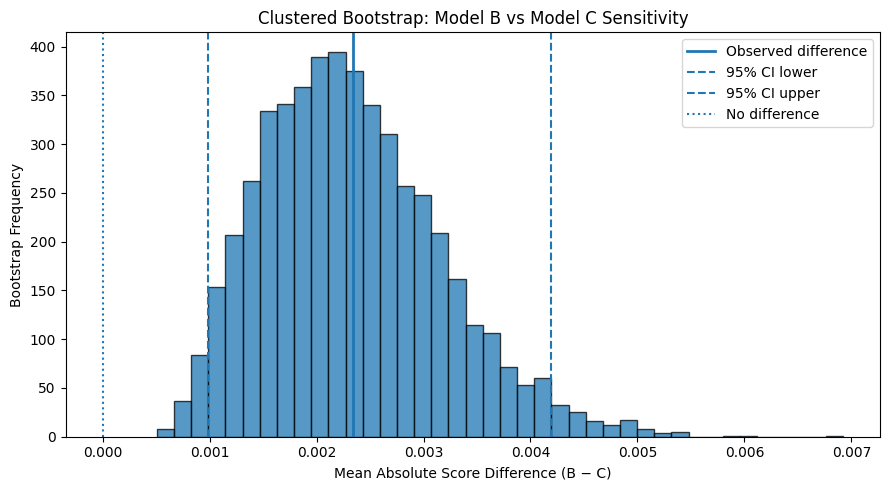

In [ ]:
plt.figure(figsize=(9, 5))

plt.hist(
    bootstrap_differences,
    bins=40,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    observed_difference,
    linestyle="-",
    linewidth=2,
    label="Observed difference"
)

plt.axvline(
    ci_lower,
    linestyle="--",
    label="95% CI lower"
)

plt.axvline(
    ci_upper,
    linestyle="--",
    label="95% CI upper"
)

plt.axvline(
    0,
    linestyle=":",
    label="No difference"
)

plt.title(
    "Clustered Bootstrap: Model B vs Model C Sensitivity"
)

plt.xlabel(
    "Mean Absolute Score Difference (B − C)"
)

plt.ylabel("Bootstrap Frequency")

plt.legend()
plt.tight_layout()

figure_path = os.path.join(
    ROBUSTNESS_DIR,
    "bootstrap_robustness_difference.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
bootstrap_summary = pd.DataFrame([{
    "observed_difference": observed_difference,
    "relative_reduction_percent": relative_reduction,
    "ci_lower_95": ci_lower,
    "ci_upper_95": ci_upper,
    "bootstrap_repetitions": N_BOOTSTRAP,
    "unique_templates": 48,
    "sentence_pairs": 144,
    "method": "context-stratified clustered bootstrap"
}])

bootstrap_summary.to_csv(
    os.path.join(
        ROBUSTNESS_DIR,
        "bootstrap_robustness_summary.csv"
    ),
    index=False
)

pd.DataFrame({
    "bootstrap_difference": bootstrap_differences
}).to_csv(
    os.path.join(
        ROBUSTNESS_DIR,
        "bootstrap_robustness_repetitions.csv"
    ),
    index=False
)

print("Bootstrap analysis saved successfully!")

Bootstrap analysis saved successfully!


# Final Experiment Configuration
## Locking Models, Thresholds and Evaluation Procedures

All hyperparameters and prediction thresholds were selected
using training and validation data only.

The held-out test datasets have not yet been evaluated.

In [ ]:
import os
import json
from datetime import datetime, timezone

PROJECT_DIR = "/content/drive/MyDrive/AI Fairness Research"

RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
FINAL_DIR = os.path.join(RESULTS_DIR, "final_evaluation")

os.makedirs(FINAL_DIR, exist_ok=True)

locked_config = {
    "experiment": "Final held-out model comparison",

    "models": {
        "A2_unweighted_lr": {
            "threshold": 0.15,
            "model_file": "logistic_regression_baseline.joblib"
        },
        "A4_balanced_lr": {
            "threshold": 0.60,
            "model_file": "logistic_regression_balanced.joblib"
        },
        "B_standard_distilbert": {
            "threshold": 0.25,
            "model_directory": "distilbert_standard/best_model"
        },
        "C_weighted_distilbert": {
            "threshold": 0.30,
            "model_directory": "distilbert_weighted/best_model"
        }
    },

    "identity_groups": [
        "male",
        "female",
        "christian",
        "muslim",
        "black",
        "white"
    ],

    "identity_threshold": 0.5,
    "toxicity_label_threshold": 0.5,

    "primary_predictive_metric": "toxic_f1",

    "subgroup_metrics": [
        "false_positive_rate",
        "false_negative_rate",
        "toxic_f1"
    ],

    "test_datasets": [
        "test_processed.csv",
        "enriched_test_processed.csv"
    ],

    "threshold_source": "validation_only",
    "locked_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": "locked_before_final_testing"
}

config_path = os.path.join(
    FINAL_DIR,
    "locked_experiment_config.json"
)

# Prevent accidental overwriting of the original lock
if os.path.exists(config_path):
    with open(config_path, "r") as f:
        locked_config = json.load(f)

    print("Existing locked configuration loaded.")
else:
    with open(config_path, "w") as f:
        json.dump(locked_config, f, indent=4)

    print("Experimental configuration locked!")

print("Configuration file:", config_path)

Experimental configuration locked!
Configuration file: /content/drive/MyDrive/AI Fairness Research/results/final_evaluation/locked_experiment_config.json


In [ ]:
MODEL_DIR = os.path.join(PROJECT_DIR, "models")

required_paths = {
    "TF-IDF": os.path.join(
        MODEL_DIR, "tfidf_vectorizer.joblib"
    ),

    "Unweighted LR": os.path.join(
        MODEL_DIR, "logistic_regression_baseline.joblib"
    ),

    "Balanced LR": os.path.join(
        MODEL_DIR, "logistic_regression_balanced.joblib"
    ),

    "Standard DistilBERT": os.path.join(
        MODEL_DIR,
        "distilbert_standard",
        "best_model",
        "model.safetensors"
    ),

    "Weighted DistilBERT": os.path.join(
        MODEL_DIR,
        "distilbert_weighted",
        "best_model",
        "model.safetensors"
    )
}

all_found = True

for name, path in required_paths.items():

    exists = os.path.isfile(path)

    print(name, "FOUND" if exists else "MISSING")

    if not exists:
        all_found = False

assert all_found, "Some model files are missing!"

print("\nAll models are ready for final evaluation!")

TF-IDF FOUND
Unweighted LR FOUND
Balanced LR FOUND
Standard DistilBERT FOUND
Weighted DistilBERT FOUND

All models are ready for final evaluation!


In [ ]:
import pandas as pd

DATA_DIR = os.path.join(PROJECT_DIR, "processed")

train_df = pd.read_csv(
    os.path.join(DATA_DIR, "train_processed.csv")
)

val_df = pd.read_csv(
    os.path.join(DATA_DIR, "val_processed.csv")
)

test_df = pd.read_csv(
    os.path.join(DATA_DIR, "test_processed.csv")
)

enriched_test_df = pd.read_csv(
    os.path.join(DATA_DIR, "enriched_test_processed.csv")
)

splits = {
    "Train": train_df,
    "Validation": val_df,
    "Representative test": test_df,
    "Enriched test": enriched_test_df
}

print("DATASET SIZES")

for name, data in splits.items():
    print(name, ":", len(data))

# Verify all IDs are unique within each split
for name, data in splits.items():
    assert data["id"].is_unique, (
        f"Duplicate IDs found in {name}"
    )

# Verify no identical texts across any splits
for name, data in splits.items():
    assert not data["comment_text"].duplicated().any(), (
        f"Duplicate comment text in {name}"
    )

names = list(splits.keys())

for i in range(len(names)):
    for j in range(i + 1, len(names)):

        a = splits[names[i]]
        b = splits[names[j]]

        overlap = set(a["id"]) & set(b["id"])

        assert len(overlap) == 0, (
            f"Overlap detected between {names[i]} and {names[j]}"
        )

print("\nAll split integrity checks passed!")

DATASET SIZES
Train : 20000
Validation : 5000
Representative test : 5000
Enriched test : 3000

All split integrity checks passed!


In [ ]:
import hashlib

def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:
        while True:

            chunk = f.read(1024 * 1024)

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()


manifest = {}

filenames = [
    "train_processed.csv",
    "val_processed.csv",
    "test_processed.csv",
    "enriched_test_processed.csv"
]

for filename in filenames:

    path = os.path.join(DATA_DIR, filename)

    manifest[filename] = {
        "sha256": sha256_file(path),
        "size_bytes": os.path.getsize(path)
    }

manifest_path = os.path.join(
    FINAL_DIR, "dataset_manifest.json"
)

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=4)

print("Dataset manifest saved!")

for name in manifest:
    print(name, manifest[name]["sha256"][:16])

Dataset manifest saved!
train_processed.csv 56ed7e947a85ed0a
val_processed.csv 917d010045df61c6
test_processed.csv 29586d00af7479d2
enriched_test_processed.csv 63b204caeeb506dc


# Final Held-Out Evaluation
## Four-Model Comparison on Representative and Enriched Test Sets

All models and thresholds were locked before testing.
No hyperparameter tuning will be performed using test results.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
import json
import hashlib
import gc
import joblib

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

PROJECT_DIR = "/content/drive/MyDrive/AI Fairness Research"

DATA_DIR = os.path.join(PROJECT_DIR, "processed")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
FINAL_DIR = os.path.join(
    PROJECT_DIR, "results", "final_evaluation"
)

os.makedirs(FINAL_DIR, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Setup completed!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
Setup completed!


In [ ]:
config_path = os.path.join(
    FINAL_DIR,
    "locked_experiment_config.json"
)

with open(config_path, "r") as f:
    locked_config = json.load(f)

thresholds = {
    name: details["threshold"]
    for name, details in locked_config["models"].items()
}

print("LOCKED THRESHOLDS")

for name, threshold in thresholds.items():
    print(name, ":", threshold)

assert thresholds == {
    "A2_unweighted_lr": 0.15,
    "A4_balanced_lr": 0.60,
    "B_standard_distilbert": 0.25,
    "C_weighted_distilbert": 0.30
}

print("\nLocked configuration verified!")

LOCKED THRESHOLDS
A2_unweighted_lr : 0.15
A4_balanced_lr : 0.6
B_standard_distilbert : 0.25
C_weighted_distilbert : 0.3

Locked configuration verified!


In [ ]:
manifest_path = os.path.join(
    FINAL_DIR, "dataset_manifest.json"
)

with open(manifest_path, "r") as f:
    manifest = json.load(f)


def calculate_sha256(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(1024 * 1024)

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()


for filename, details in manifest.items():

    path = os.path.join(DATA_DIR, filename)

    assert os.path.isfile(path), (
        f"Missing dataset: {filename}"
    )

    actual_hash = calculate_sha256(path)

    assert actual_hash == details["sha256"], (
        f"Dataset changed: {filename}"
    )

    print(filename, "VERIFIED")

print("\nAll dataset hashes verified!")

train_processed.csv VERIFIED
val_processed.csv VERIFIED
test_processed.csv VERIFIED
enriched_test_processed.csv VERIFIED

All dataset hashes verified!


In [ ]:
test_df = pd.read_csv(
    os.path.join(
        DATA_DIR,
        "test_processed.csv"
    )
)

enriched_test_df = pd.read_csv(
    os.path.join(
        DATA_DIR,
        "enriched_test_processed.csv"
    )
)

assert len(test_df) == 5000
assert len(enriched_test_df) == 3000

assert test_df["comment_text"].notna().all()
assert enriched_test_df["comment_text"].notna().all()

assert set(test_df["label"].unique()) == {0, 1}
assert set(enriched_test_df["label"].unique()) == {0, 1}

print("Representative test:", len(test_df))
print("Enriched test:", len(enriched_test_df))

print("\nRepresentative test distribution:")
print(test_df["label"].value_counts())

print("\nEnriched test distribution:")
print(enriched_test_df["label"].value_counts())

print("\nTest datasets loaded successfully!")

Representative test: 5000
Enriched test: 3000

Representative test distribution:
label
0    4601
1     399
Name: count, dtype: int64

Enriched test distribution:
label
0    1800
1    1200
Name: count, dtype: int64

Test datasets loaded successfully!


In [ ]:
tfidf = joblib.load(
    os.path.join(
        MODEL_DIR, "tfidf_vectorizer.joblib"
    )
)

lr_unweighted = joblib.load(
    os.path.join(
        MODEL_DIR,
        "logistic_regression_baseline.joblib"
    )
)

lr_balanced = joblib.load(
    os.path.join(
        MODEL_DIR,
        "logistic_regression_balanced.joblib"
    )
)

print("All classical models loaded!")

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.6.1 when using version 1.9.1. This might lead to breaking c

All classical models loaded!


In [ ]:
def predict_lr_scores(model, dataframe):

    texts = dataframe["comment_text"].astype(str)

    # Use original training vocabulary
    features = tfidf.transform(texts)

    # Get probability for toxic class
    scores = model.predict_proba(features)[:, 1]

    return np.asarray(scores, dtype=np.float64)

In [ ]:
test_sets = {
    "representative": test_df,
    "enriched": enriched_test_df
}

all_scores = {
    "representative": {},
    "enriched": {}
}

for split_name, dataframe in test_sets.items():

    all_scores[split_name]["A2_unweighted_lr"] = (
        predict_lr_scores(lr_unweighted, dataframe)
    )

    all_scores[split_name]["A4_balanced_lr"] = (
        predict_lr_scores(lr_balanced, dataframe)
    )

    print(
        split_name,
        "- Logistic Regression predictions completed"
    )

representative - Logistic Regression predictions completed
enriched - Logistic Regression predictions completed


In [ ]:
def predict_bert_scores(model_path, texts, batch_size=16):

    tokenizer = AutoTokenizer.from_pretrained(
        model_path
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_path
    )

    model.to(device)
    model.eval()

    # Confirm toxic class is index 1
    assert model.config.num_labels == 2
    assert model.config.label2id["TOXIC"] == 1

    results = []

    for start in range(0, len(texts), batch_size):

        batch_texts = texts[
            start:start + batch_size
        ]

        encoded = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=256,
            return_tensors="pt"
        )

        encoded = {
            k: v.to(device)
            for k, v in encoded.items()
        }

        with torch.inference_mode():

            outputs = model(**encoded)

            probabilities = torch.softmax(
                outputs.logits.float(),
                dim=1
            )[:, 1]

        results.extend(
            probabilities.cpu().numpy().tolist()
        )

    del model

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return np.asarray(results, dtype=np.float64)

In [ ]:
STANDARD_MODEL_DIR = os.path.join(
    MODEL_DIR,
    "distilbert_standard",
    "best_model"
)

for split_name, dataframe in test_sets.items():

    scores = predict_bert_scores(
        STANDARD_MODEL_DIR,
        dataframe["comment_text"].astype(str).tolist()
    )

    all_scores[split_name]["B_standard_distilbert"] = scores

    print(
        "Model B:",
        split_name,
        len(scores),
        "scores generated"
    )

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model B: representative 5000 scores generated


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model B: enriched 3000 scores generated


In [ ]:
WEIGHTED_MODEL_DIR = os.path.join(
    MODEL_DIR,
    "distilbert_weighted",
    "best_model"
)

for split_name, dataframe in test_sets.items():

    scores = predict_bert_scores(
        WEIGHTED_MODEL_DIR,
        dataframe["comment_text"].astype(str).tolist()
    )

    all_scores[split_name]["C_weighted_distilbert"] = scores

    print(
        "Model C:",
        split_name,
        len(scores),
        "scores generated"
    )

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model C: representative 5000 scores generated


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model C: enriched 3000 scores generated


In [ ]:
for split_name, dataframe in test_sets.items():

    expected_n = len(dataframe)

    for model_name in thresholds:

        scores = all_scores[split_name][model_name]

        assert len(scores) == expected_n

        assert np.isfinite(scores).all()

        assert np.all(
            (scores >= 0) & (scores <= 1)
        )

        print(
            split_name,
            model_name,
            "VERIFIED"
        )

print("\nAll final prediction arrays verified!")

representative A2_unweighted_lr VERIFIED
representative A4_balanced_lr VERIFIED
representative B_standard_distilbert VERIFIED
representative C_weighted_distilbert VERIFIED
enriched A2_unweighted_lr VERIFIED
enriched A4_balanced_lr VERIFIED
enriched B_standard_distilbert VERIFIED
enriched C_weighted_distilbert VERIFIED

All final prediction arrays verified!


In [ ]:
def evaluate_model(y_true, scores, threshold):

    predictions = (
        scores >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "Threshold": threshold,

        "Accuracy": accuracy_score(
            y_true, predictions
        ),

        "Precision": precision_score(
            y_true, predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_true, predictions,
            zero_division=0
        ),

        "Toxic F1": f1_score(
            y_true, predictions,
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_true, predictions,
            average="macro",
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_true, scores
        ),

        "Average Precision": average_precision_score(
            y_true, scores
        ),

        "FPR": (
            fp / (fp + tn)
            if fp + tn > 0
            else np.nan
        ),

        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn)
    }

In [ ]:
final_results = []

for split_name, dataframe in test_sets.items():

    y_true = dataframe["label"].to_numpy()

    for model_name, threshold in thresholds.items():

        scores = all_scores[split_name][model_name]

        result = evaluate_model(
            y_true,
            scores,
            threshold
        )

        result["Dataset"] = split_name
        result["Model"] = model_name

        final_results.append(result)

final_results_df = pd.DataFrame(final_results)

print("FINAL HELD-OUT MODEL COMPARISON")

display(
    final_results_df[
        [
            "Dataset",
            "Model",
            "Threshold",
            "Accuracy",
            "Precision",
            "Recall",
            "Toxic F1",
            "Macro F1",
            "ROC-AUC",
            "Average Precision",
            "FPR",
            "TP",
            "FP",
            "FN"
        ]
    ].round(4)
)

FINAL HELD-OUT MODEL COMPARISON


,Dataset,Model,Threshold,Accuracy,Precision,Recall,Toxic F1,Macro F1,ROC-AUC,Average Precision,FPR,TP,FP,FN
0,representative,A2_unweighted_lr,0.15,0.9168,0.4773,0.4486,0.4625,0.7087,0.8493,0.4879,0.0426,179,196,220
1,representative,A4_balanced_lr,0.60,0.9224,0.5179,0.3985,0.4504,0.7043,0.8496,0.4915,0.0322,159,148,240
2,representative,B_standard_distilbert,0.25,0.9386,0.6230,0.5840,0.6028,0.7848,0.9333,0.6802,0.0306,233,141,166
3,representative,C_weighted_distilbert,0.30,0.9382,0.6203,0.5815,0.6003,0.7834,0.9302,0.6742,0.0309,232,142,167
4,enriched,A2_unweighted_lr,0.15,0.7067,0.7030,0.4617,0.5573,0.6690,0.7599,0.6820,0.1300,554,234,646
5,enriched,A4_balanced_lr,0.60,0.7017,0.7201,0.4158,0.5272,0.6546,0.7614,0.6851,0.1078,499,194,701
6,enriched,B_standard_distilbert,0.25,0.7270,0.8547,0.3825,0.5285,0.6682,0.8439,0.7908,0.0433,459,78,741
7,enriched,C_weighted_distilbert,0.30,0.7197,0.8732,0.3500,0.4997,0.6525,0.8434,0.7906,0.0339,420,61,780


In [ ]:
final_results_df.to_csv(
    os.path.join(
        FINAL_DIR,
        "final_overall_model_comparison.csv"
    ),
    index=False
)

print("Overall held-out results saved!")

Overall held-out results saved!


In [ ]:
identity_columns = [
    "male",
    "female",
    "christian",
    "muslim",
    "black",
    "white"
]

subgroup_results = []

for split_name, dataframe in test_sets.items():

    y_true = dataframe["label"].to_numpy()

    for model_name, threshold in thresholds.items():

        scores = all_scores[split_name][model_name]

        predictions = (
            scores >= threshold
        ).astype(int)

        for group in identity_columns:

            # Select observed identity mentions
            mask = (
                dataframe[group].notna()
                & dataframe[group].ge(0.5)
            ).to_numpy()

            group_true = y_true[mask]
            group_pred = predictions[mask]

            tn, fp, fn, tp = confusion_matrix(
                group_true,
                group_pred,
                labels=[0, 1]
            ).ravel()

            n_negative = tn + fp
            n_positive = fn + tp

            subgroup_results.append({
                "Dataset": split_name,
                "Model": model_name,
                "Group": group,

                "Total": int(mask.sum()),
                "Non-toxic": int(n_negative),
                "Toxic": int(n_positive),

                "TP": int(tp),
                "FP": int(fp),
                "TN": int(tn),
                "FN": int(fn),

                "FPR": (
                    fp / n_negative
                    if n_negative > 0
                    else np.nan
                ),

                "FNR": (
                    fn / n_positive
                    if n_positive > 0
                    else np.nan
                ),

                "Toxic F1": f1_score(
                    group_true,
                    group_pred,
                    zero_division=0
                ) if len(group_true) else np.nan
            })

subgroup_results_df = pd.DataFrame(
    subgroup_results
)

print("FINAL SUBGROUP FAIRNESS RESULTS")

display(subgroup_results_df.round(4))

FINAL SUBGROUP FAIRNESS RESULTS


,Dataset,Model,Group,Total,Non-toxic,Toxic,TP,FP,TN,FN,FPR,FNR,Toxic F1
0,representative,A2_unweighted_lr,male,114,95,19,9,5,90,10,0.0526,0.5263,0.5455
1,representative,A2_unweighted_lr,female,146,123,23,8,8,115,15,0.0650,0.6522,0.4103
2,representative,A2_unweighted_lr,christian,101,87,14,5,2,85,9,0.0230,0.6429,0.4762
3,representative,A2_unweighted_lr,muslim,67,51,16,5,3,48,11,0.0588,0.6875,0.4167
4,representative,A2_unweighted_lr,black,39,26,13,5,5,21,8,0.1923,0.6154,0.4348
5,representative,A2_unweighted_lr,white,67,49,18,11,15,34,7,0.3061,0.3889,0.5000
6,representative,A4_balanced_lr,male,114,95,19,9,5,90,10,0.0526,0.5263,0.5455
7,representative,A4_balanced_lr,female,146,123,23,8,6,117,15,0.0488,0.6522,0.4324
8,representative,A4_balanced_lr,christian,101,87,14,5,2,85,9,0.0230,0.6429,0.4762
9,representative,A4_balanced_lr,muslim,67,51,16,4,2,49,12,0.0392,0.7500,0.3636


In [ ]:
enriched_bc = subgroup_results_df[
    (subgroup_results_df["Dataset"] == "enriched")
    & (
        subgroup_results_df["Model"].isin([
            "B_standard_distilbert",
            "C_weighted_distilbert"
        ])
    )
]

fpr_comparison = enriched_bc.pivot(
    index="Group",
    columns="Model",
    values="FPR"
)

# Convert to percentages
fpr_percent = fpr_comparison * 100

fpr_percent["Difference (B-C), pp"] = (
    fpr_percent["B_standard_distilbert"]
    - fpr_percent["C_weighted_distilbert"]
)

print("FINAL ENRICHED TEST SUBGROUP FPR (%)")

display(fpr_percent.round(2))

FINAL ENRICHED TEST SUBGROUP FPR (%)


Model,B_standard_distilbert,C_weighted_distilbert,"Difference (B-C), pp"
Group,,,
black,5.24,3.81,1.43
christian,2.08,1.39,0.69
female,3.84,3.49,0.35
male,5.67,4.61,1.06
muslim,3.31,3.31,0.00
white,5.38,4.38,1.00


In [ ]:
gap_rows = []

for dataset_name in ["representative", "enriched"]:

    for model_name in thresholds:

        subset = subgroup_results_df[
            (subgroup_results_df["Dataset"] == dataset_name)
            & (subgroup_results_df["Model"] == model_name)
        ]

        valid_fpr = subset["FPR"].dropna()

        gap_rows.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Highest FPR": valid_fpr.max(),
            "Lowest FPR": valid_fpr.min(),
            "FPR Gap": valid_fpr.max() - valid_fpr.min()
        })

final_gap_df = pd.DataFrame(gap_rows)

print("FINAL SUBGROUP FPR DISPARITY GAPS")

display(final_gap_df.round(4))

FINAL SUBGROUP FPR DISPARITY GAPS


,Dataset,Model,Highest FPR,Lowest FPR,FPR Gap
0,representative,A2_unweighted_lr,0.3061,0.0230,0.2831
1,representative,A4_balanced_lr,0.2449,0.0230,0.2219
2,representative,B_standard_distilbert,0.0632,0.0115,0.0517
3,representative,C_weighted_distilbert,0.0612,0.0115,0.0497
4,enriched,A2_unweighted_lr,0.2548,0.0577,0.1970
5,enriched,A4_balanced_lr,0.2119,0.0462,0.1657
6,enriched,B_standard_distilbert,0.0567,0.0208,0.0360
7,enriched,C_weighted_distilbert,0.0461,0.0139,0.0322


In [ ]:
subgroup_results_df.to_csv(
    os.path.join(
        FINAL_DIR,
        "final_subgroup_fairness.csv"
    ),
    index=False
)

final_gap_df.to_csv(
    os.path.join(
        FINAL_DIR,
        "final_subgroup_fpr_gaps.csv"
    ),
    index=False
)

fpr_percent.to_csv(
    os.path.join(
        FINAL_DIR,
        "final_enriched_model_b_vs_c_fpr.csv"
    )
)

print("All subgroup fairness results saved!")

All subgroup fairness results saved!


In [ ]:
for split_name, dataframe in test_sets.items():

    prediction_table = dataframe[
        ["id", "label"]
    ].copy()

    for model_name in thresholds:

        prediction_table[
            f"{model_name}_score"
        ] = all_scores[split_name][model_name]

    output_path = os.path.join(
        FINAL_DIR,
        f"{split_name}_locked_model_predictions.csv"
    )

    prediction_table.to_csv(
        output_path,
        index=False
    )

    print(split_name, "predictions saved!")

representative predictions saved!
enriched predictions saved!


In [ ]:
required_files = [
    "locked_experiment_config.json",
    "dataset_manifest.json",
    "final_overall_model_comparison.csv",
    "final_subgroup_fairness.csv",
    "final_subgroup_fpr_gaps.csv",
    "final_enriched_model_b_vs_c_fpr.csv",
    "representative_locked_model_predictions.csv",
    "enriched_locked_model_predictions.csv"
]

for filename in required_files:

    path = os.path.join(FINAL_DIR, filename)

    assert os.path.isfile(path), (
        f"Missing file: {filename}"
    )

    print("VERIFIED:", filename)

print("\nAll final evaluation files saved successfully!")

VERIFIED: locked_experiment_config.json
VERIFIED: dataset_manifest.json
VERIFIED: final_overall_model_comparison.csv
VERIFIED: final_subgroup_fairness.csv
VERIFIED: final_subgroup_fpr_gaps.csv
VERIFIED: final_enriched_model_b_vs_c_fpr.csv
VERIFIED: representative_locked_model_predictions.csv
VERIFIED: enriched_locked_model_predictions.csv

All final evaluation files saved successfully!


# Statistical Reliability of Final Test Results
## Paired Bootstrap Confidence Intervals

In [ ]:
import os
import numpy as np
import pandas as pd


from sklearn.metrics import (
    f1_score,
    confusion_matrix
)

PROJECT_DIR = "/content/drive/MyDrive/AI Fairness Research"

FINAL_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "final_evaluation"
)

DATA_DIR = os.path.join(
    PROJECT_DIR,
    "processed"
)

# Load locked predictions
representative_predictions = pd.read_csv(
    os.path.join(
        FINAL_DIR,
        "representative_locked_model_predictions.csv"
    )
)

enriched_predictions = pd.read_csv(
    os.path.join(
        FINAL_DIR,
        "enriched_locked_model_predictions.csv"
    )
)

# Load corresponding dataset rows
test_df = pd.read_csv(
    os.path.join(DATA_DIR, "test_processed.csv")
)

enriched_test_df = pd.read_csv(
    os.path.join(DATA_DIR, "enriched_test_processed.csv")
)

# Verify prediction alignment
assert np.array_equal(
    test_df["id"].to_numpy(),
    representative_predictions["id"].to_numpy()
)

assert np.array_equal(
    enriched_test_df["id"].to_numpy(),
    enriched_predictions["id"].to_numpy()
)

assert len(representative_predictions) == 5000
assert len(enriched_predictions) == 3000

print("Final test predictions loaded successfully!")

Final test predictions loaded successfully!


In [ ]:
THRESHOLD_B = 0.25
THRESHOLD_C = 0.30

B_COL = "B_standard_distilbert_score"
C_COL = "C_weighted_distilbert_score"

for predictions in [
    representative_predictions,
    enriched_predictions
]:
    assert B_COL in predictions.columns
    assert C_COL in predictions.columns

print("Locked prediction columns verified!")

Locked prediction columns verified!


In [ ]:
from sklearn.metrics import f1_score

RANDOM_STATE = 42
N_BOOTSTRAP = 5000

rng = np.random.default_rng(RANDOM_STATE)

y_true = representative_predictions[
    "label"
].to_numpy()

B_scores = representative_predictions[
    B_COL
].to_numpy()

C_scores = representative_predictions[
    C_COL
].to_numpy()

B_predictions = (
    B_scores >= THRESHOLD_B
).astype(int)

C_predictions = (
    C_scores >= THRESHOLD_C
).astype(int)

n = len(y_true)

bootstrap_f1_differences = []

for _ in range(N_BOOTSTRAP):

    # Resample the same comments for both models
    indices = rng.choice(
        n,
        size=n,
        replace=True
    )

    sampled_labels = y_true[indices]

    sampled_B = B_predictions[indices]
    sampled_C = C_predictions[indices]

    f1_B = f1_score(
        sampled_labels,
        sampled_B,
        zero_division=0
    )

    f1_C = f1_score(
        sampled_labels,
        sampled_C,
        zero_division=0
    )

    bootstrap_f1_differences.append(
        f1_C - f1_B
    )

bootstrap_f1_differences = np.array(
    bootstrap_f1_differences
)

print("Bootstrap repetitions:", len(bootstrap_f1_differences))
print("Paired F1 bootstrap completed!")

Bootstrap repetitions: 5000
Paired F1 bootstrap completed!


In [ ]:
observed_B_f1 = f1_score(
    y_true,
    B_predictions
)

observed_C_f1 = f1_score(
    y_true,
    C_predictions
)

observed_f1_difference = (
    observed_C_f1 - observed_B_f1
)

f1_ci_lower, f1_ci_upper = np.percentile(
    bootstrap_f1_differences,
    [2.5, 97.5]
)

print("REPRESENTATIVE TEST — F1 COMPARISON")
print("----------------------------------")

print("Model B F1:", round(observed_B_f1, 6))
print("Model C F1:", round(observed_C_f1, 6))

print(
    "Observed difference (C-B):",
    round(observed_f1_difference, 6)
)

print(
    "95% CI:",
    (
        round(f1_ci_lower, 6),
        round(f1_ci_upper, 6)
    )
)

print(
    "Interval includes zero:",
    bool(f1_ci_lower <= 0 <= f1_ci_upper)
)

REPRESENTATIVE TEST — F1 COMPARISON
----------------------------------
Model B F1: 0.602846
Model C F1: 0.600259
Observed difference (C-B): -0.002587
95% CI: (np.float64(-0.015576), np.float64(0.009725))
Interval includes zero: True


In [ ]:
identity_columns = [
    "male",
    "female",
    "christian",
    "muslim",
    "black",
    "white"
]

enriched_labels = enriched_predictions[
    "label"
].to_numpy()

enriched_B = (
    enriched_predictions[B_COL].to_numpy()
    >= THRESHOLD_B
).astype(int)

enriched_C = (
    enriched_predictions[C_COL].to_numpy()
    >= THRESHOLD_C
).astype(int)

group_masks = {}

for group in identity_columns:

    group_masks[group] = (
        enriched_test_df[group].notna()
        & (enriched_test_df[group] >= 0.5)
    ).to_numpy()

print("All six subgroup masks prepared!")

All six subgroup masks prepared!


In [ ]:
def subgroup_fpr_gap(
    labels,
    predictions,
    masks
):

    fpr_values = []

    for group in identity_columns:

        mask = masks[group]

        # Consider only non-toxic comments
        negative_mask = (
            mask & (labels == 0)
        )

        denominator = negative_mask.sum()

        if denominator == 0:
            return np.nan

        false_positives = (
            negative_mask
            & (predictions == 1)
        ).sum()

        fpr_values.append(
            false_positives / denominator
        )

    return max(fpr_values) - min(fpr_values)

In [ ]:
observed_B_gap = subgroup_fpr_gap(
    enriched_labels,
    enriched_B,
    group_masks
)

observed_C_gap = subgroup_fpr_gap(
    enriched_labels,
    enriched_C,
    group_masks
)

observed_gap_difference = (
    observed_C_gap - observed_B_gap
)

print("ENRICHED TEST — FPR GAP")

print(
    "Model B gap:",
    round(observed_B_gap, 6)
)

print(
    "Model C gap:",
    round(observed_C_gap, 6)
)

print(
    "Difference (C-B):",
    round(observed_gap_difference, 6)
)

ENRICHED TEST — FPR GAP
Model B gap: 0.035952
Model C gap: 0.032242
Difference (C-B): -0.00371


In [ ]:
rng = np.random.default_rng(43)

n_enriched = len(enriched_labels)

bootstrap_gap_differences = []

for _ in range(N_BOOTSTRAP):

    indices = rng.choice(
        n_enriched,
        size=n_enriched,
        replace=True
    )

    sampled_labels = enriched_labels[indices]

    sampled_B = enriched_B[indices]
    sampled_C = enriched_C[indices]

    sampled_masks = {
        group: mask[indices]
        for group, mask in group_masks.items()
    }

    gap_B = subgroup_fpr_gap(
        sampled_labels,
        sampled_B,
        sampled_masks
    )

    gap_C = subgroup_fpr_gap(
        sampled_labels,
        sampled_C,
        sampled_masks
    )

    if np.isfinite(gap_B) and np.isfinite(gap_C):
        bootstrap_gap_differences.append(
            gap_C - gap_B
        )

bootstrap_gap_differences = np.array(
    bootstrap_gap_differences
)

print(
    "Valid bootstrap repetitions:",
    len(bootstrap_gap_differences)
)

Valid bootstrap repetitions: 5000


In [ ]:
gap_ci_lower, gap_ci_upper = np.percentile(
    bootstrap_gap_differences,
    [2.5, 97.5]
)

print("ENRICHED TEST — FPR GAP UNCERTAINTY")
print("-----------------------------------")

print(
    "Observed difference (C-B):",
    round(observed_gap_difference, 6)
)

print(
    "95% CI:",
    (
        round(gap_ci_lower, 6),
        round(gap_ci_upper, 6)
    )
)

print(
    "Interval includes zero:",
    bool(gap_ci_lower <= 0 <= gap_ci_upper)
)

ENRICHED TEST — FPR GAP UNCERTAINTY
-----------------------------------
Observed difference (C-B): -0.00371
95% CI: (np.float64(-0.018862), np.float64(0.006745))
Interval includes zero: True


In [ ]:
statistical_summary = pd.DataFrame([
    {
        "Dataset": "Representative",
        "Metric": "Toxic F1 difference (C-B)",
        "Observed difference": observed_f1_difference,
        "CI lower": f1_ci_lower,
        "CI upper": f1_ci_upper,
        "Bootstrap repetitions": N_BOOTSTRAP
    },
    {
        "Dataset": "Enriched",
        "Metric": "Subgroup FPR gap difference (C-B)",
        "Observed difference": observed_gap_difference,
        "CI lower": gap_ci_lower,
        "CI upper": gap_ci_upper,
        "Bootstrap repetitions": len(
            bootstrap_gap_differences
        )
    }
])

display(statistical_summary.round(6))

,Dataset,Metric,Observed difference,CI lower,CI upper,Bootstrap repetitions
0,Representative,Toxic F1 difference (C-B),-0.002587,-0.015576,0.009725,5000
1,Enriched,Subgroup FPR gap difference (C-B),-0.003710,-0.018862,0.006745,5000


In [ ]:
statistical_summary.to_csv(
    os.path.join(
        FINAL_DIR,
        "paired_bootstrap_statistical_summary.csv"
    ),
    index=False
)

pd.DataFrame({
    "f1_difference": bootstrap_f1_differences
}).to_csv(
    os.path.join(
        FINAL_DIR,
        "bootstrap_f1_differences.csv"
    ),
    index=False
)

pd.DataFrame({
    "fpr_gap_difference": bootstrap_gap_differences
}).to_csv(
    os.path.join(
        FINAL_DIR,
        "bootstrap_fpr_gap_differences.csv"
    ),
    index=False
)

print("Statistical analysis saved successfully!")

Statistical analysis saved successfully!


#  Final Research Figures
## Model Performance, Fairness and Robustness

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/AI Fairness Research"

FINAL_DIR = os.path.join(
    PROJECT_DIR, "results", "final_evaluation"
)

ROBUSTNESS_DIR = os.path.join(
    PROJECT_DIR, "results", "robustness"
)

FIGURES_DIR = os.path.join(
    PROJECT_DIR, "figures", "final"
)

os.makedirs(FIGURES_DIR, exist_ok=True)

overall_df = pd.read_csv(
    os.path.join(
        FINAL_DIR,
        "final_overall_model_comparison.csv"
    )
)

subgroup_df = pd.read_csv(
    os.path.join(
        FINAL_DIR,
        "final_subgroup_fairness.csv"
    )
)

stats_df = pd.read_csv(
    os.path.join(
        FINAL_DIR,
        "paired_bootstrap_statistical_summary.csv"
    )
)

robustness_df = pd.read_csv(
    os.path.join(
        ROBUSTNESS_DIR,
        "identity_swap_main_results.csv"
    )
)

print("All research results loaded!")

All research results loaded!


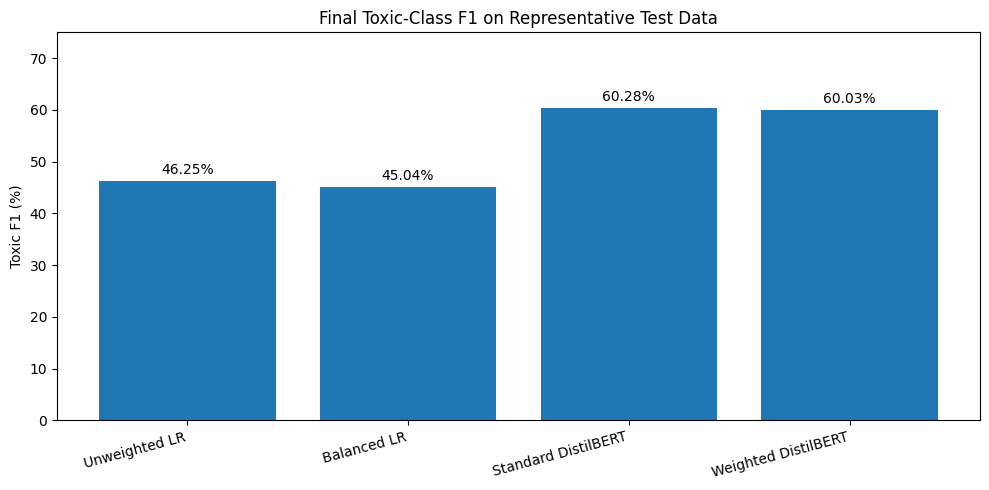

In [ ]:
representative = overall_df[
    overall_df["Dataset"] == "representative"
].copy()

names = [
    "Unweighted LR",
    "Balanced LR",
    "Standard DistilBERT",
    "Weighted DistilBERT"
]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    names,
    representative["Toxic F1"].to_numpy() * 100
)

ax.set_title(
    "Final Toxic-Class F1 on Representative Test Data"
)
ax.set_ylabel("Toxic F1 (%)")
ax.set_ylim(0, 75)

ax.bar_label(bars, fmt="%.2f%%", padding=3)

plt.xticks(rotation=15, ha="right")
plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR, "figure_1_model_performance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

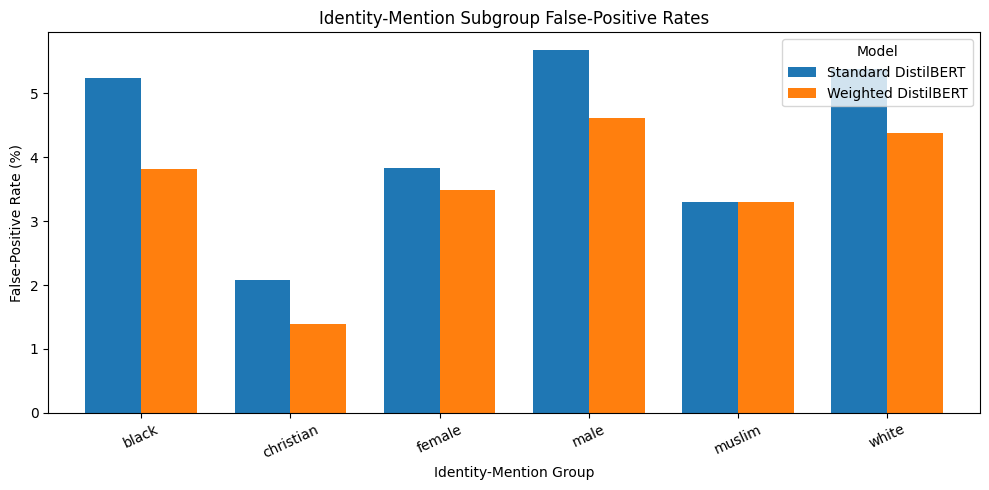

In [ ]:
bc_fairness = subgroup_df[
    (subgroup_df["Dataset"] == "enriched")
    & subgroup_df["Model"].isin([
        "B_standard_distilbert",
        "C_weighted_distilbert"
    ])
]

fpr_table = bc_fairness.pivot(
    index="Group",
    columns="Model",
    values="FPR"
) * 100

fpr_table = fpr_table.rename(columns={
    "B_standard_distilbert": "Standard DistilBERT",
    "C_weighted_distilbert": "Weighted DistilBERT"
})

ax = fpr_table.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_title(
    "Identity-Mention Subgroup False-Positive Rates"
)
ax.set_xlabel("Identity-Mention Group")
ax.set_ylabel("False-Positive Rate (%)")

plt.xticks(rotation=25)
plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR, "figure_2_subgroup_fairness.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

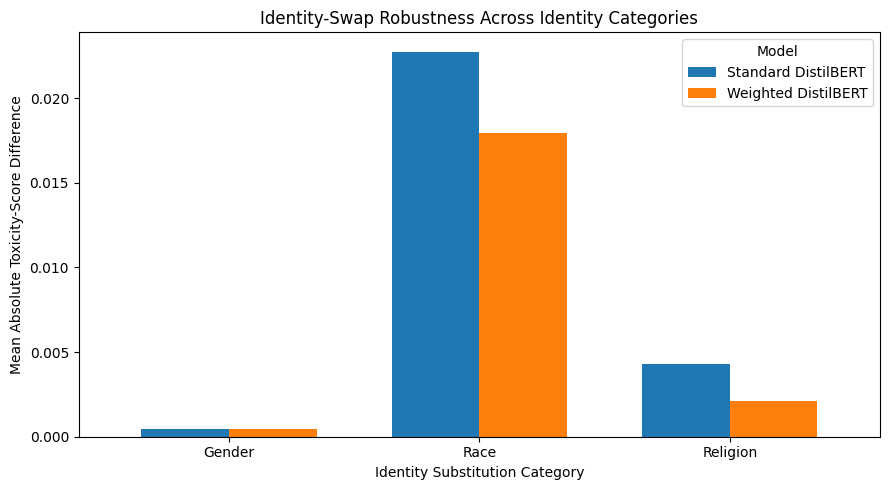

In [ ]:
robustness_summary = robustness_df.groupby("category")[
    ["B_abs_diff", "C_abs_diff"]
].mean()

robustness_summary.columns = [
    "Standard DistilBERT",
    "Weighted DistilBERT"
]

ax = robustness_summary.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

ax.set_title(
    "Identity-Swap Robustness Across Identity Categories"
)
ax.set_xlabel("Identity Substitution Category")
ax.set_ylabel("Mean Absolute Toxicity-Score Difference")

plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR, "figure_3_identity_swap_robustness.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
print("FINAL STATISTICAL SUMMARY")

display(stats_df.round(6))

assert len(stats_df) == 2

print("\nAll main statistical results verified!")

FINAL STATISTICAL SUMMARY


,Dataset,Metric,Observed difference,CI lower,CI upper,Bootstrap repetitions
0,Representative,Toxic F1 difference (C-B),-0.002587,-0.015576,0.009725,5000
1,Enriched,Subgroup FPR gap difference (C-B),-0.003710,-0.018862,0.006745,5000



All main statistical results verified!
